En este ejercicio se analizaron los precios y rendimientos de 211 empresas del índice Nikkei durante el periodo 2010-2012. Primero, se calcularon las matrices de correlación para todo el horizonte temporal y se representaron mediante mapas de calor. Posteriormente, se obtuvieron los valores propios de dichas matrices y se estudió su distribución mediante histogramas. Después, el horizonte temporal se dividió en épocas de aproximadamente 60 días hábiles para analizar la evolución de las correlaciones y los valores propios. Finalmente, se construyó un diagrama de dispersión entre la correlación promedio y el valor propio máximo de cada época. Los resultados muestran una tendencia positiva entre ambas cantidades, lo que sugiere que una mayor correlación entre las empresas está asociada con un comportamiento colectivo más intenso del mercado.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

## Parte previa
Vamos a leer los datos y vamos a ver la información que tienen, si hay que hacer modificaciones, alguna información sobre los datos que tenemos, si hay que cambiar valores, renglones o columnas

In [2]:
df_original = pd.read_csv(r"Data/Nikkei-2010-2012.csv", index_col= "Ticker")
df_original.head(10)

,2010-01-04,2010-01-05,2010-01-06,2010-01-07,2010-01-08,2010-01-12,2010-01-13,2010-01-14,2010-01-15,2010-01-18,...,2012-12-14,2012-12-17,2012-12-18,2012-12-19,2012-12-20,2012-12-21,2012-12-25,2012-12-26,2012-12-27,2012-12-28
Ticker,,,,,,,,,,,,,,,,,,,,,
4151.t,999.000000,989.000000,1003.000000,984.000000,991.000000,984.000000,985.000000,990.0,989.000000,975.000000,...,845.0,848.000000,852.000000,861.000000,850.000000,852.000000,856.000000,850.000000,851.000000,849.000000
4502.t,3850.000000,3870.000000,3870.000000,3930.000000,3900.000000,3940.000000,3930.000000,3970.0,3970.000000,3945.000000,...,3805.0,3835.000000,3845.000000,3870.000000,3875.000000,3865.000000,3865.000000,3865.000000,3860.000000,3855.000000
4503.t,694.000000,700.000000,700.000000,700.000000,702.000000,700.000000,696.000000,704.0,702.000000,697.000000,...,797.0,800.000000,809.000000,812.000000,802.000000,792.000000,797.000000,798.000000,780.000000,775.000000
4506.t,979.000000,984.000000,991.000000,982.000000,981.000000,977.000000,979.000000,982.0,980.000000,965.000000,...,999.0,1013.000000,1019.000000,1026.000000,1012.000000,1010.000000,1021.000000,1032.000000,1033.000000,1035.000000
4507.t,2003.000000,2007.000000,2007.000000,1957.000000,1930.000000,1931.000000,1904.000000,1968.0,1957.000000,1926.000000,...,1349.0,1382.000000,1443.000000,1462.000000,1461.000000,1457.000000,1454.000000,1469.000000,1479.000000,1437.000000
4519.t,580.666687,572.333313,577.333313,572.333313,567.333313,562.666687,553.333313,558.0,556.666687,550.333313,...,545.0,558.666687,550.333313,558.333313,553.666687,546.666687,552.000000,549.333313,553.333313,550.333313
4523.t,3435.000000,3425.000000,3460.000000,3440.000000,3425.000000,3410.000000,3375.000000,3390.0,3390.000000,3365.000000,...,3465.0,3505.000000,3510.000000,3530.000000,3555.000000,3585.000000,3595.000000,3625.000000,3645.000000,3600.000000
4568.t,649.666687,653.333313,653.333313,660.000000,651.666687,661.333313,661.666687,666.0,661.000000,650.000000,...,432.0,432.666656,433.333344,440.666656,436.666656,436.333344,437.333344,440.000000,440.333344,440.666656
3105.t,861.000000,868.000000,873.000000,856.000000,886.000000,890.000000,888.000000,905.0,899.000000,875.000000,...,642.0,645.000000,656.000000,685.000000,679.000000,667.000000,678.000000,698.000000,715.000000,724.000000


In [3]:
df_original.info()

<class 'pandas.DataFrame'>
Index: 211 entries, 4151.t to 9532.t
Columns: 736 entries, 2010-01-04 to 2012-12-28
dtypes: float64(736)
memory usage: 1.2+ MB


In [4]:
df_original.describe()

,2010-01-04,2010-01-05,2010-01-06,2010-01-07,2010-01-08,2010-01-12,2010-01-13,2010-01-14,2010-01-15,2010-01-18,...,2012-12-14,2012-12-17,2012-12-18,2012-12-19,2012-12-20,2012-12-21,2012-12-25,2012-12-26,2012-12-27,2012-12-28
count,211.000000,211.000000,211.000000,211.000000,211.000000,211.000000,211.000000,211.000000,211.000000,211.000000,...,211.000000,211.000000,211.00000,211.000000,211.000000,211.000000,211.000000,211.000000,211.000000,211.000000
mean,1878.523379,1888.325350,1904.467339,1907.000933,1931.197947,1949.034027,1923.128976,1956.806748,1968.415658,1946.542853,...,1632.199284,1646.961396,1659.20633,1704.079977,1692.354807,1676.827566,1694.775378,1725.130212,1744.329696,1755.817105
std,1809.162467,1795.428942,1797.496914,1788.831865,1814.904072,1802.088458,1771.368637,1789.484005,1805.080851,1779.120616,...,1899.520840,1934.144780,1944.81428,1983.694845,1933.547122,1906.860458,1951.586272,1990.795897,2004.999333,2039.876959
min,117.000000,115.125000,116.000000,115.375000,115.916664,115.208336,119.541664,118.250000,120.333336,121.458336,...,113.000000,111.000000,116.00000,120.000000,121.000000,123.000000,121.000000,124.000000,129.000000,127.000000
25%,803.500000,801.500000,803.500000,793.000000,809.500000,816.500000,804.500000,810.000000,817.500000,812.000000,...,723.500000,732.000000,745.50000,773.500000,767.000000,755.500000,757.000000,790.500000,818.500000,818.500000
50%,1415.000000,1405.000000,1424.000000,1441.000000,1450.000000,1480.000000,1460.000000,1477.000000,1490.000000,1471.000000,...,1174.000000,1180.000000,1178.00000,1202.000000,1182.000000,1182.000000,1204.000000,1210.000000,1223.000000,1240.000000
75%,2399.000000,2429.000000,2447.000000,2425.500000,2485.000000,2522.500000,2494.000000,2528.500000,2550.000000,2513.000000,...,2051.500000,2076.000000,2075.00000,2145.500000,2155.000000,2128.500000,2153.500000,2210.000000,2235.000000,2245.500000
max,17460.000000,16900.000000,16770.000000,16690.000000,16900.000000,16050.000000,16010.000000,15770.000000,16220.000000,15830.000000,...,19920.000000,20500.000000,20830.00000,21230.000000,20370.000000,20090.000000,20770.000000,21170.000000,21270.000000,21840.000000


In [5]:
df_original.dtypes

2010-01-04    float64
2010-01-05    float64
2010-01-06    float64
2010-01-07    float64
2010-01-08    float64
               ...   
2012-12-21    float64
2012-12-25    float64
2012-12-26    float64
2012-12-27    float64
2012-12-28    float64
Length: 736, dtype: object

## Ejercicio 1 



### Correlaciones entre empresas, y correlaciones de rendimientos

Como la matriz de correlación es relacionar las empresas entre si, en este caso mi DF tenemos renglones = empresas, y columnas = fechas, queremos las correlaciones entre empresas, así que necesitamos transponerlos


In [6]:
df_precios = df_original.copy()
df_precios = df_precios.reset_index(drop=True)

In [7]:
C_precios = df_precios.T.corr() 
C_precios

,0,1,2,3,4,5,6,7,8,9,...,201,202,203,204,205,206,207,208,209,210
0,1.000000,0.092193,0.277986,0.495838,0.262856,0.406216,0.375985,0.196407,0.197529,0.202926,...,0.019017,0.176178,0.048556,0.006656,0.394857,0.297165,0.247247,0.097690,0.254975,0.411108
1,0.092193,1.000000,0.038481,-0.140545,0.880000,0.666366,-0.073722,0.696854,0.650572,0.721836,...,0.770398,0.756582,0.775400,0.577133,0.767150,0.751722,0.691102,0.688403,0.254157,0.223988
2,0.277986,0.038481,1.000000,0.686079,-0.037003,0.532405,0.774044,-0.459159,-0.521559,-0.340889,...,-0.466490,-0.450997,-0.474008,-0.669875,0.225355,-0.287842,-0.472730,-0.564465,0.688866,0.634702
3,0.495838,-0.140545,0.686079,1.000000,-0.124298,0.212766,0.744282,-0.216481,-0.372272,-0.365692,...,-0.485677,-0.442890,-0.512577,-0.560379,0.086629,-0.338247,-0.352715,-0.468737,0.182145,0.346715
4,0.262856,0.880000,-0.037003,-0.124298,1.000000,0.721150,-0.106881,0.731811,0.720202,0.815516,...,0.786571,0.839650,0.830401,0.614549,0.789825,0.882282,0.801262,0.774078,0.240944,0.185538
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
206,0.297165,0.751722,-0.287842,-0.338247,0.882282,0.570183,-0.327149,0.801280,0.816590,0.858433,...,0.854558,0.917300,0.891879,0.803200,0.713618,1.000000,0.929295,0.900254,0.109974,0.073949
207,0.247247,0.691102,-0.472730,-0.352715,0.801262,0.372005,-0.435639,0.878087,0.902695,0.879302,...,0.895215,0.942110,0.910078,0.875981,0.605153,0.929295,1.000000,0.977209,-0.100710,-0.051251
208,0.097690,0.688403,-0.564465,-0.468737,0.774078,0.282068,-0.554811,0.890004,0.930219,0.900819,...,0.946461,0.960903,0.953041,0.927834,0.569963,0.900254,0.977209,1.000000,-0.189732,-0.171482
209,0.254975,0.254157,0.688866,0.182145,0.240944,0.723732,0.555150,-0.293889,-0.215855,-0.018973,...,-0.126667,-0.050152,-0.094051,-0.307555,0.348276,0.109974,-0.100710,-0.189732,1.000000,0.851869


En pandas tenemos una función que calcula los rendimientos, lo único que hace falta es transponerla matriz y sacamos la correlación 

In [8]:
df_rendimientos = df_precios.pct_change(axis=1).iloc[:, 1:]
df_rendimientos.head(5)

,2010-01-05,2010-01-06,2010-01-07,2010-01-08,2010-01-12,2010-01-13,2010-01-14,2010-01-15,2010-01-18,2010-01-19,...,2012-12-14,2012-12-17,2012-12-18,2012-12-19,2012-12-20,2012-12-21,2012-12-25,2012-12-26,2012-12-27,2012-12-28
0,-0.010010,0.014156,-0.018943,0.007114,-0.007064,0.001016,0.005076,-0.001010,-0.014156,-0.003077,...,0.001185,0.003550,0.004717,0.010563,-0.012776,0.002353,0.004695,-0.007009,0.001176,-0.002350
1,0.005195,0.000000,0.015504,-0.007634,0.010256,-0.002538,0.010178,0.000000,-0.006297,-0.002535,...,0.000000,0.007884,0.002608,0.006502,0.001292,-0.002581,0.000000,0.000000,-0.001294,-0.001295
2,0.008646,0.000000,0.000000,0.002857,-0.002849,-0.005714,0.011494,-0.002841,-0.007123,-0.004304,...,-0.001253,0.003764,0.011250,0.003708,-0.012315,-0.012469,0.006313,0.001255,-0.022556,-0.006410
3,0.005107,0.007114,-0.009082,-0.001018,-0.004077,0.002047,0.003064,-0.002037,-0.015306,0.006218,...,0.007056,0.014014,0.005923,0.006869,-0.013645,-0.001976,0.010891,0.010774,0.000969,0.001936
4,0.001997,0.000000,-0.024913,-0.013797,0.000518,-0.013982,0.033613,-0.005589,-0.015841,0.004673,...,-0.010997,0.024463,0.044139,0.013167,-0.000684,-0.002738,-0.002059,0.010316,0.006807,-0.028398


In [9]:
C_rendimientos = df_rendimientos.T.corr() 
C_rendimientos.head(5)

,0,1,2,3,4,5,6,7,8,9,...,201,202,203,204,205,206,207,208,209,210
0,1.000000,0.506467,0.516745,0.605482,0.525539,0.618230,0.456683,0.553833,0.510954,0.393269,...,0.291836,0.337150,0.280742,0.337236,0.616710,0.156070,0.210776,0.183127,0.321677,0.398190
1,0.506467,1.000000,0.580885,0.517866,0.534009,0.543140,0.613947,0.606118,0.424025,0.342969,...,0.324047,0.326547,0.307029,0.328910,0.555032,0.167686,0.228508,0.202237,0.318349,0.376670
2,0.516745,0.580885,1.000000,0.537725,0.450711,0.478505,0.556201,0.544136,0.357023,0.267566,...,0.244101,0.235406,0.210162,0.186115,0.539561,0.110390,0.167756,0.109764,0.237018,0.288842
3,0.605482,0.517866,0.537725,1.000000,0.534920,0.581412,0.459322,0.598977,0.437026,0.313205,...,0.261149,0.300526,0.269973,0.285358,0.548233,0.138467,0.227113,0.200831,0.308781,0.400987
4,0.525539,0.534009,0.450711,0.534920,1.000000,0.564239,0.446122,0.537401,0.415984,0.303941,...,0.286922,0.328234,0.295422,0.271793,0.489441,0.139247,0.224827,0.222484,0.283436,0.347419


In [10]:
# También podemos construir la matriz a mano 
# Matriz de datos
D = df_precios.to_numpy()

# Estandarizar cada serie (cada fila)
media = D.mean(axis=1, keepdims=True)
desv = D.std(axis=1, keepdims=True)

D_std = (D - media) / desv

# Número de tiempos
T = D.shape[1]

# Matriz de correlación
C = (1/T) * D_std @ D_std.T
C[0][:10]

array([1.        , 0.09219277, 0.2779862 , 0.49583773, 0.26285581,
       0.40621614, 0.37598462, 0.19640685, 0.19752866, 0.20292633])

In [11]:
# Comparemos que sean los mismos valores que obtuvimos 
np.allclose(C, C_precios.to_numpy())

True

### Mapas de calor

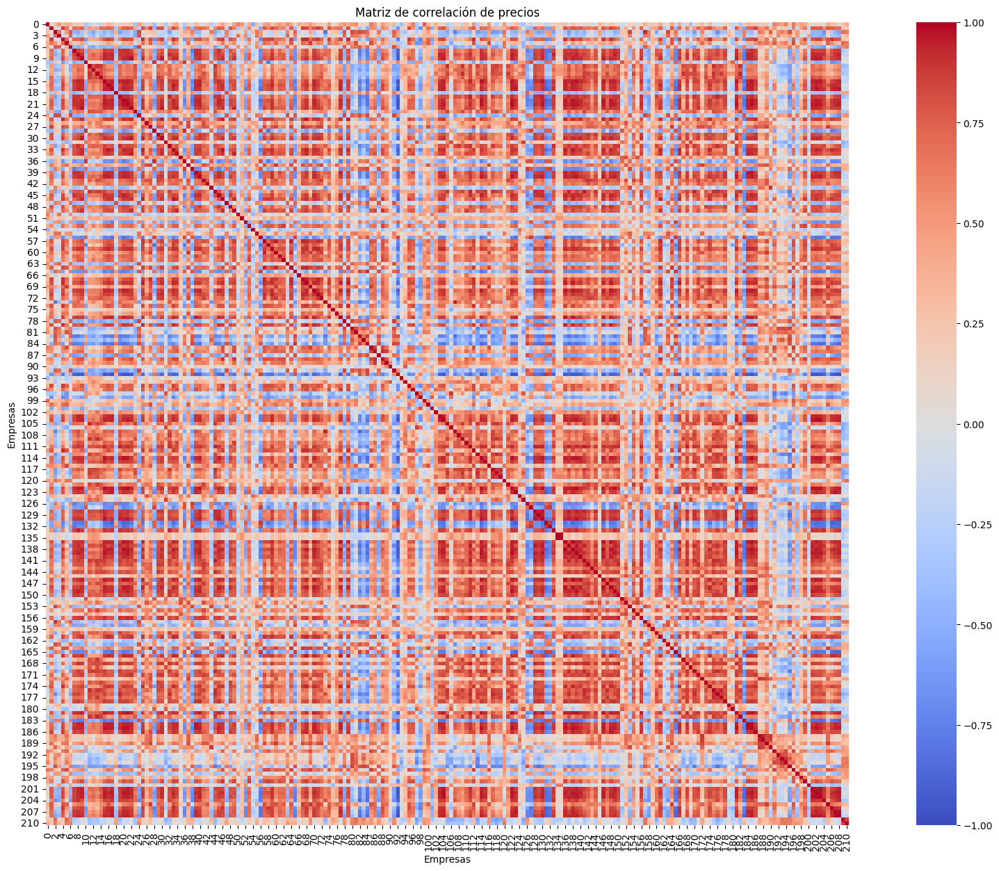

In [12]:
plt.figure(figsize=(25, 15))
sns.heatmap(C_precios, square=True, cmap='coolwarm' , vmin=-1, vmax=1)
plt.title("Matriz de correlación de precios")
plt.xlabel("Empresas")
plt.ylabel("Empresas")
plt.show()

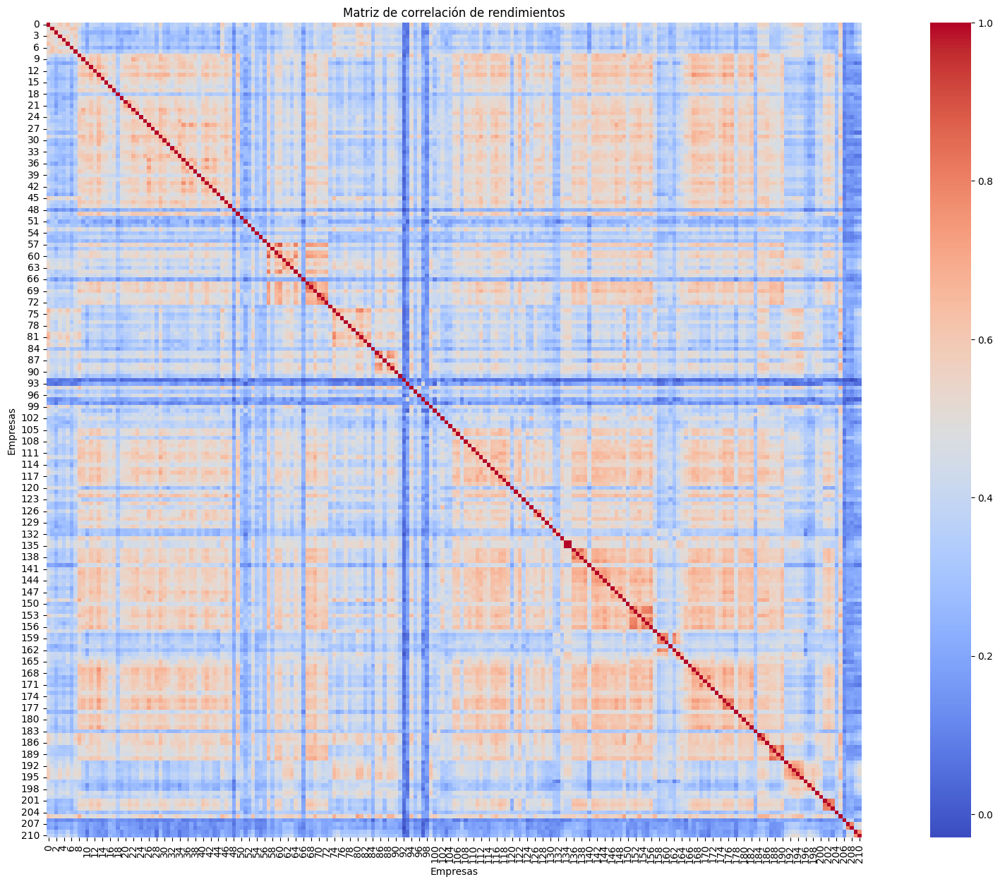

In [13]:
plt.figure(figsize=(25, 15))
sns.heatmap(C_rendimientos, square=True, cmap='coolwarm')
plt.title("Matriz de correlación de rendimientos")
plt.xlabel("Empresas")
plt.ylabel("Empresas")
plt.show()

### Valores propios 

In [14]:
autovalores_precios = np.linalg.eigvalsh(C_precios)
autovalores_rendimientos = np.linalg.eigvalsh(C_rendimientos)

In [15]:
df_autovalores = pd.DataFrame({"Precios AV": autovalores_precios, "Rendimientos AV": autovalores_rendimientos})
df_autovalores.head(10)

,Precios AV,Rendimientos AV
0,6.066111e-17,4.498189e-16
1,3.540326e-04,5.516175e-02
2,3.995255e-04,5.958808e-02
3,4.229430e-04,6.196368e-02
4,4.747361e-04,6.576658e-02
5,5.020581e-04,6.807767e-02
6,5.904623e-04,7.187773e-02
7,6.166879e-04,7.264375e-02
8,6.449532e-04,7.525184e-02
9,6.775256e-04,7.653162e-02


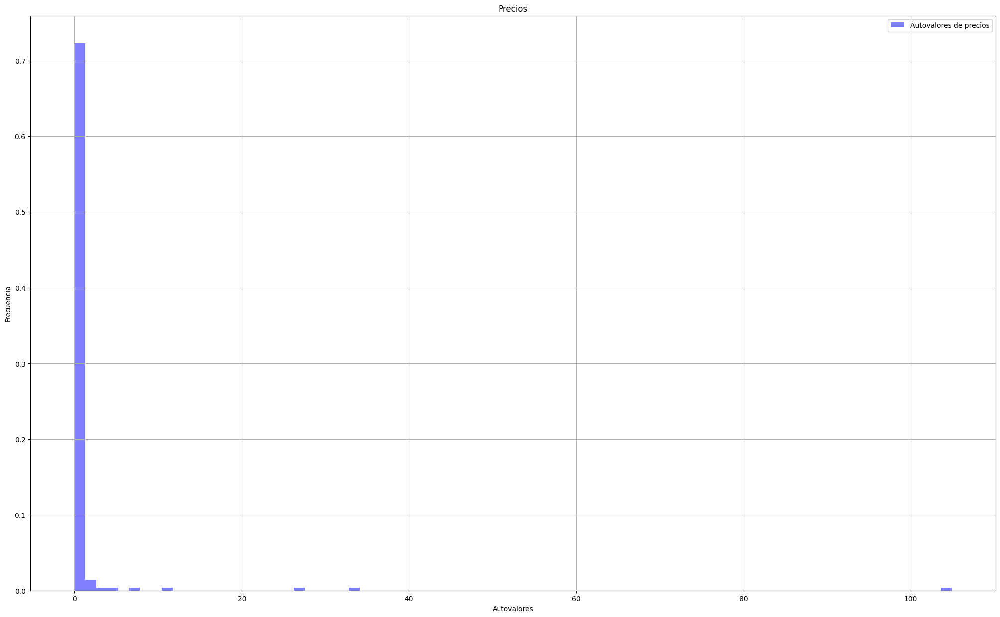

In [16]:
plt.figure(figsize=(25, 15))
plt.hist(df_autovalores["Precios AV"],  bins=80, density=True, alpha=0.5, color = "blue", label = "Autovalores de precios")
plt.title("Precios")
plt.xlabel("Autovalores")
plt.ylabel("Frecuencia")
plt.legend(loc = "best")
plt.grid()


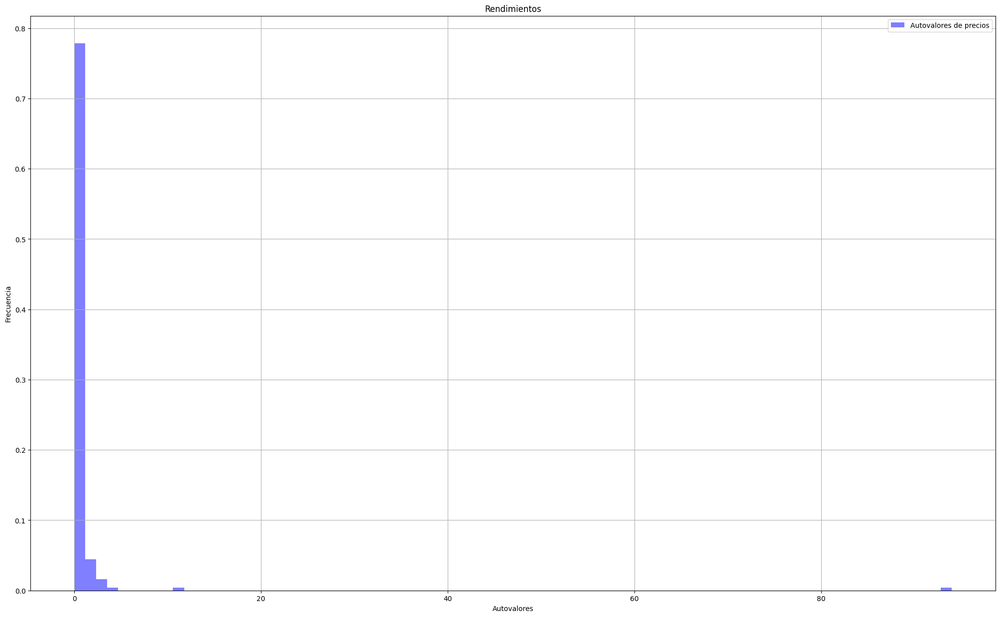

In [17]:
plt.figure(figsize=(25, 15))
plt.hist(df_autovalores["Rendimientos AV"],  bins=80, density=True, alpha=0.5, color = "blue", label = "Autovalores de precios")
plt.title("Rendimientos")
plt.xlabel("Autovalores")
plt.ylabel("Frecuencia")
plt.legend(loc = "best")
plt.grid()

## (B) Horizonte temporal T en épocas de 60 días hábiles

Creamos cada uno de los DataFremes, tomando en cuenta los 60 días habiles para cada fecha

In [18]:
df_1 = df_original.loc[:, "2010-01-04": "2010-03-26"]
df_2 = df_original.loc[:, "2010-03-29": "2010-06-18"]
df_3 = df_original.loc[:, "2010-06-21":" 2010-09-10"]
df_4 = df_original.loc[:, "2010-09-13":	"2010-12-03"]
df_5 = df_original.loc[:, "2010-12-06":	"2011-02-25"]
df_6 = df_original.loc[:, "2011-02-28":"2011-05-20"]
df_7 = df_original.loc[:, "2011-05-23":	"2011-08-12"]
df_8 = df_original.loc[:, "2011-08-15": "2011-11-04"]
df_9 = df_original.loc[:, "2011-11-07":"2012-01-27"]
df_10 = df_original.loc[:, "2012-01-30":"2012-04-20"]
df_11 = df_original.loc[:, "2012-04-23":"2012-07-13"]
df_12 = df_original.loc[:, "2012-07-16":"2012-10-05"]
df_13 = df_original.loc[:, "2012-10-08":"2012-12-28"]

In [ ]:
def df_def_precios(df):
    df_precios = df.copy()
    df_precios = df_precios.reset_index(drop=True)
    return df_precios

def C_def_precios(df_precios):
    C_precios = df_precios.T.corr() 
    return C_precios

def df_def_rendimientos(df_precios):
    df_rendimientos = df_precios.pct_change(axis=1).iloc[:, 1:]
    return df_rendimientos

def C_def_rendimientos(df_rendimientos):
    C_rendimientos = df_rendimientos.T.corr() 
    return C_rendimientos

def mapa_de_calor_precios(C_precios):
    plt.figure(figsize=(25, 15))
    sns.heatmap(C_precios, square=True, cmap='coolwarm' , vmin=-1, vmax=1)
    plt.title("Matriz de correlación de precios")
    plt.xlabel("Empresas")
    plt.ylabel("Empresas")
    return plt.show()
def mapa_de_calor_rendimientos(C_rendimientos):
    plt.figure(figsize=(25, 15))
    sns.heatmap(C_rendimientos, square=True, cmap='coolwarm')
    plt.title("Matriz de correlación de rendimientos")
    plt.xlabel("Empresas")
    plt.ylabel("Empresas")
    return plt.show()

def autovalores_precios(C_precios):
    autovalores_precios = np.linalg.eigvalsh(C_precios)
    return autovalores_precios

def autovalores_rendimientos(C_rendimientos):
    autovalores_rendimientos = np.linalg.eigvalsh(C_rendimientos)
    return autovalores_rendimientos

def df_def_autovalores(autovalores_precios, autovalores_rendimientos):
    df_autovalores = pd.DataFrame({"Precios AV": autovalores_precios, "Rendimientos AV": autovalores_rendimientos})
    return df_autovalores

def densidad_de_autovalores_precios(df_autovalores):
    plt.figure(figsize=(25, 15))
    plt.hist(df_autovalores["Precios AV"],  bins=80, density=True, alpha=0.5, color = "blue", label = "Autovalores de precios")
    plt.title("Precios")
    plt.xlabel("Autovalores")
    plt.ylabel("Frecuencia")
    plt.legend(loc = "best")
    plt.grid()
    return plt.show()
def densidad_de_autovalores_rendimientos(df_autovalores):
    plt.figure(figsize=(25, 15))
    plt.hist(df_autovalores["Rendimientos AV"],  bins=80, density=True, alpha=0.5, color = "blue", label = "Autovalores de rendimientos")
    plt.title("Rendimientos")
    plt.xlabel("Autovalores")
    plt.ylabel("Frecuencia")
    plt.legend(loc = "best")
    plt.grid()
    return plt.show()


In [26]:
def analisis_nikkei(df):

    # DataFrames de precios y rendimientos
    df_precios = df_def_precios(df)
    df_rendimientos = df_def_rendimientos(df_precios)

    # Matrices de correlación
    C_precios = C_def_precios(df_precios)
    C_rendimientos = C_def_rendimientos(df_rendimientos)

    # Mapas de calor
    mapa_de_calor_precios(C_precios)
    mapa_de_calor_rendimientos(C_rendimientos)

    # Autovalores
    AV_precios = autovalores_precios(C_precios)
    AV_rendimientos = autovalores_rendimientos(C_rendimientos)

    # DataFrame de autovalores
    df_autovalores = df_def_autovalores(AV_precios, AV_rendimientos)

    # Histogramas
    densidad_de_autovalores_precios(df_autovalores)
    densidad_de_autovalores_rendimientos(df_autovalores)

    return df_precios, df_rendimientos, C_precios, C_rendimientos, df_autovalores

In [ ]:
dataframes = [df_1, df_2, df_3, df_4, df_5, df_6, df_7, df_8, df_9, df_10, df_11, df_12, df_13]

Época 1


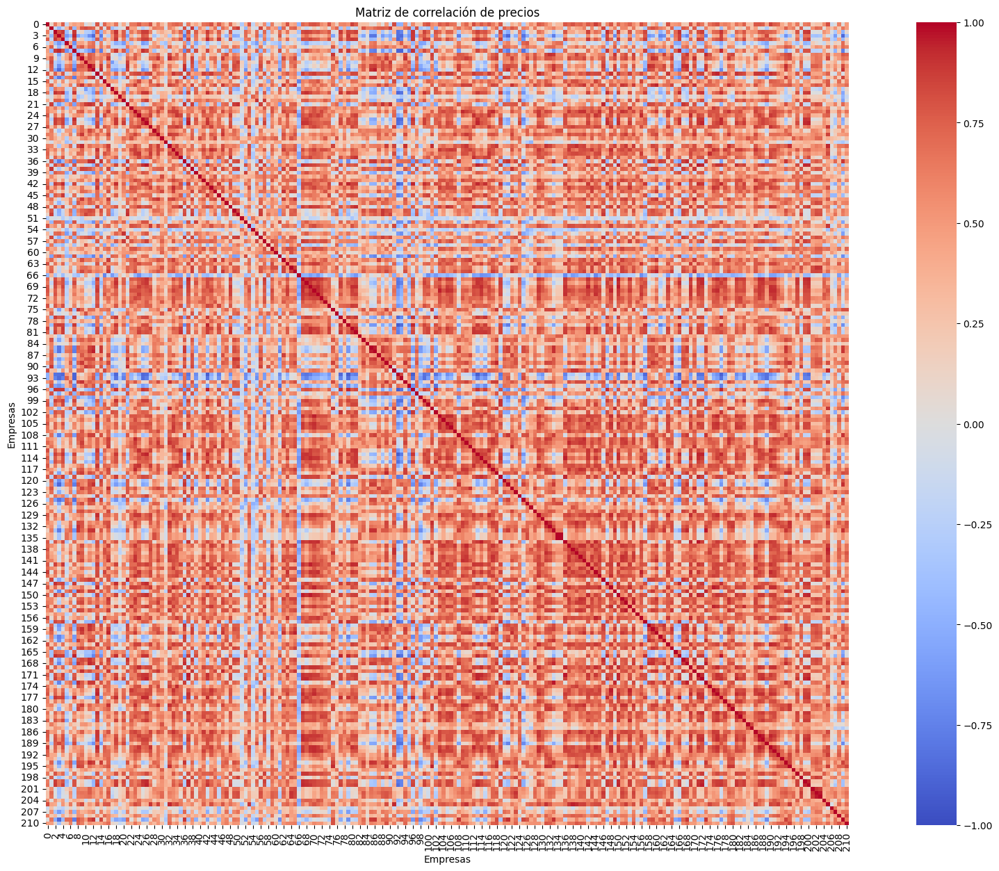

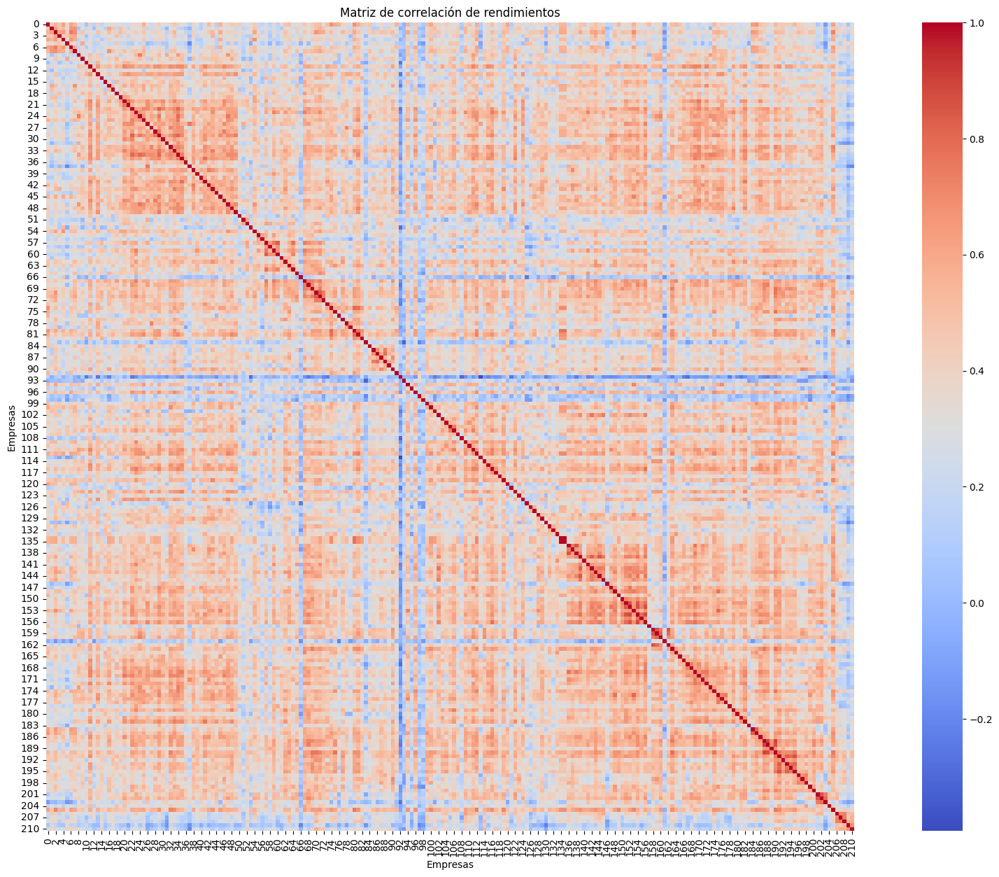

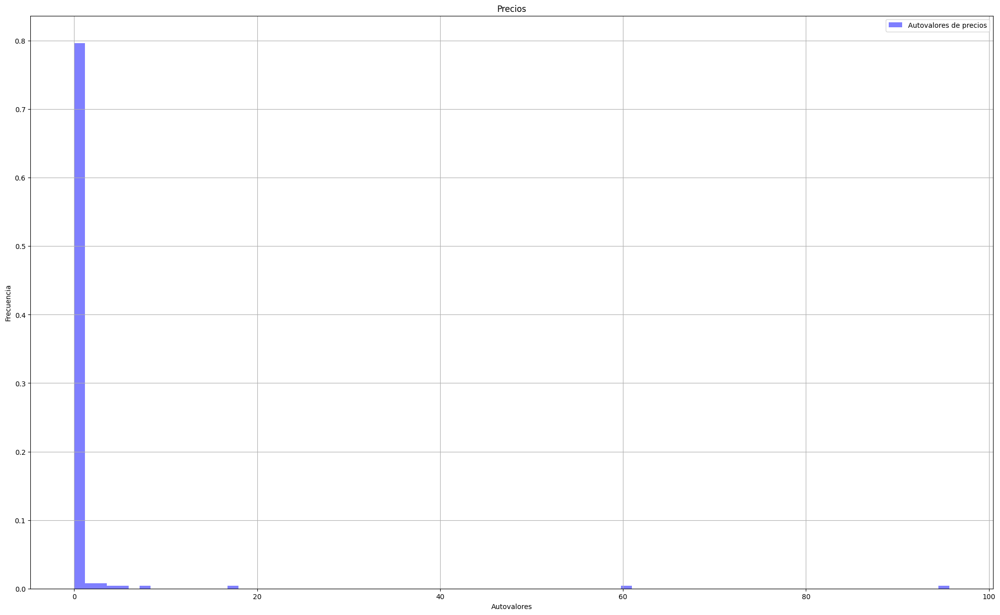

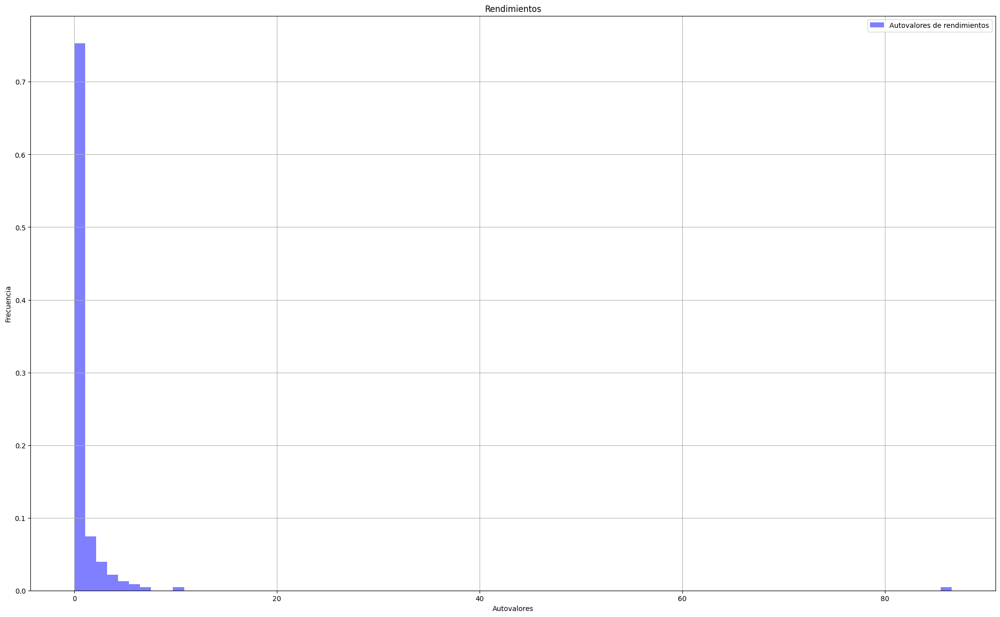

Época 2


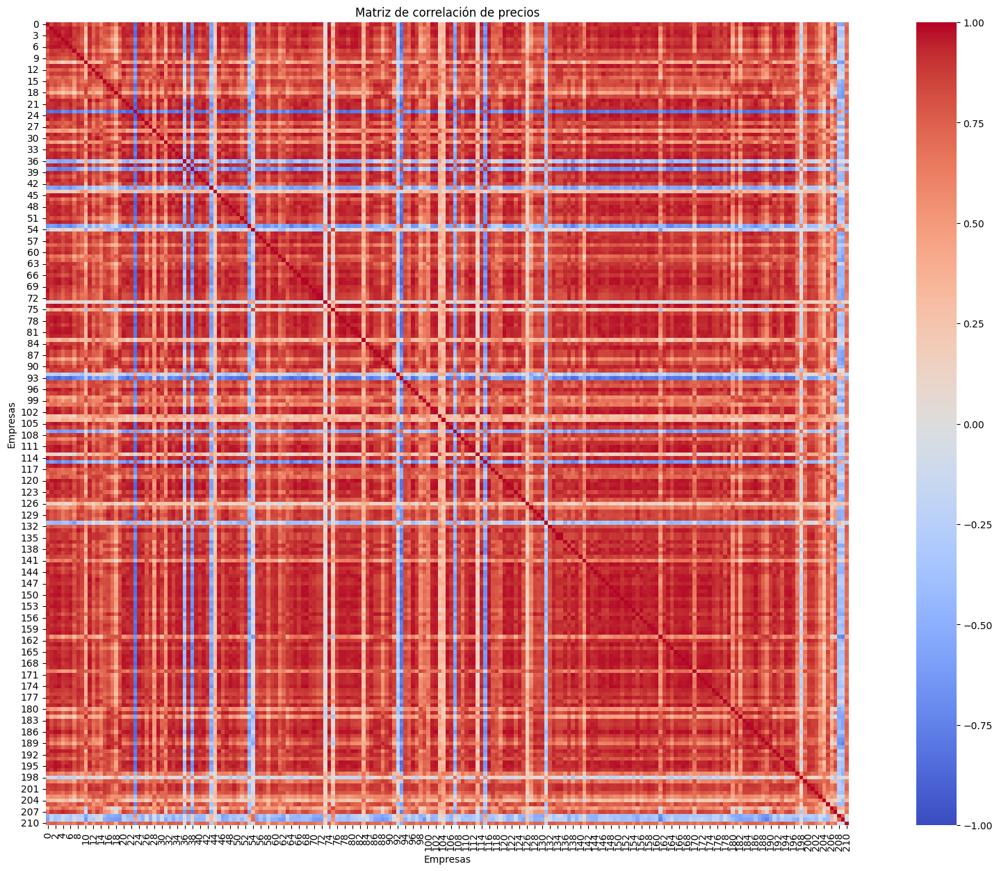

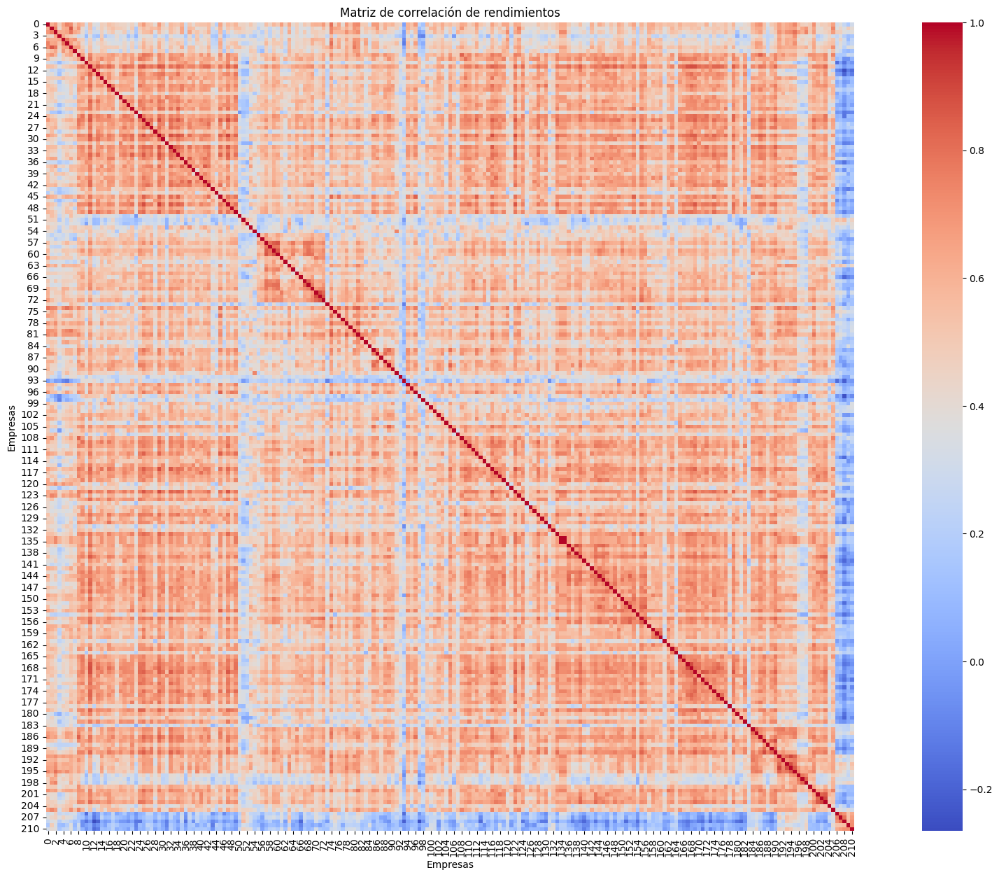

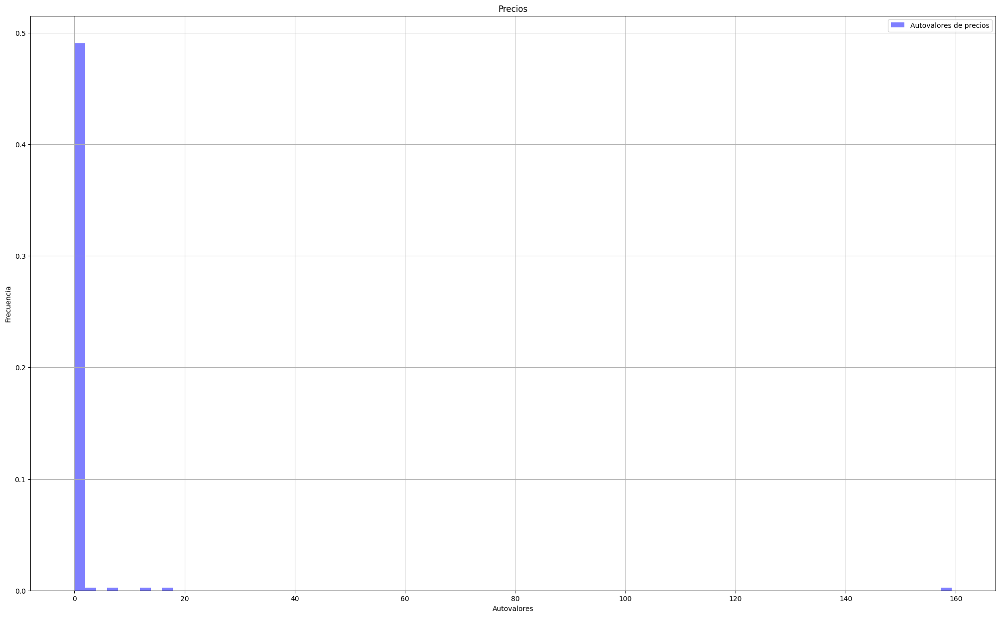

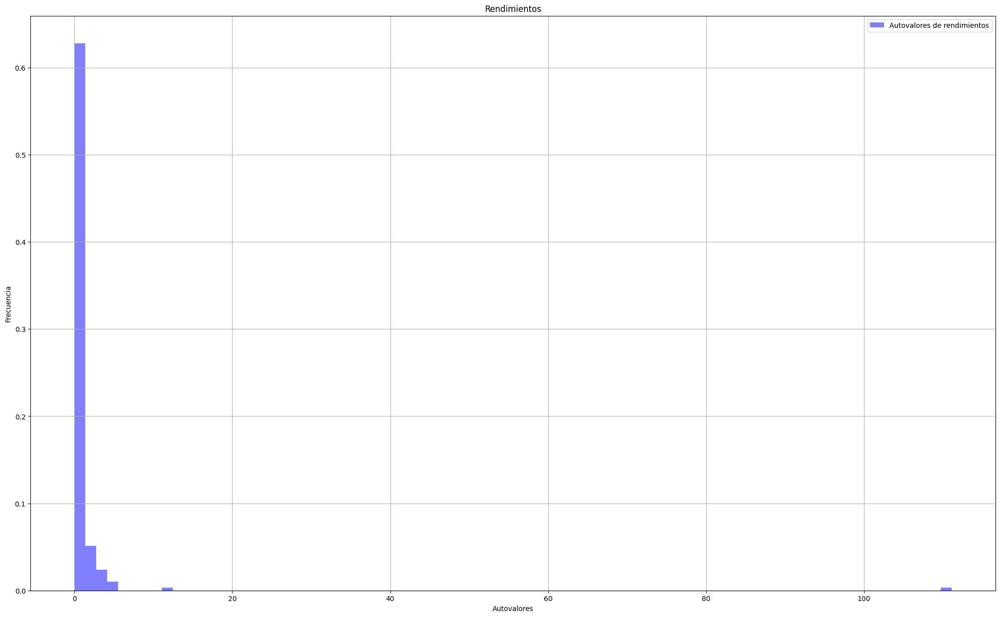

Época 4


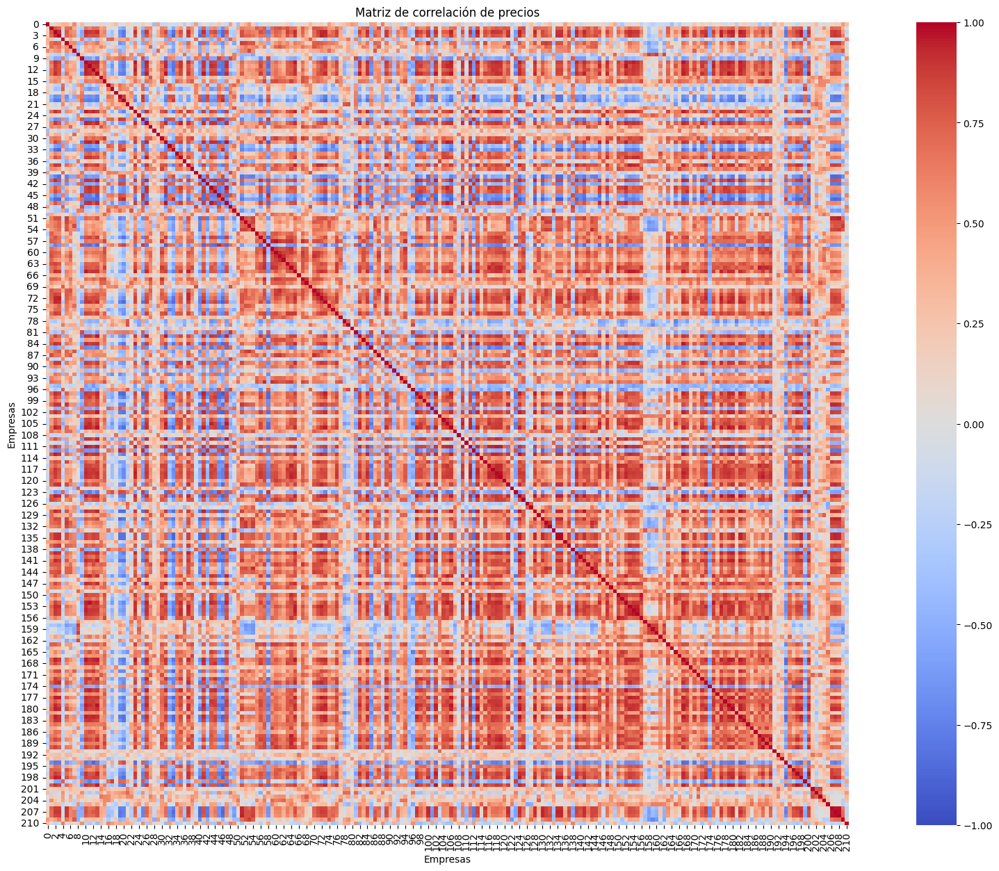

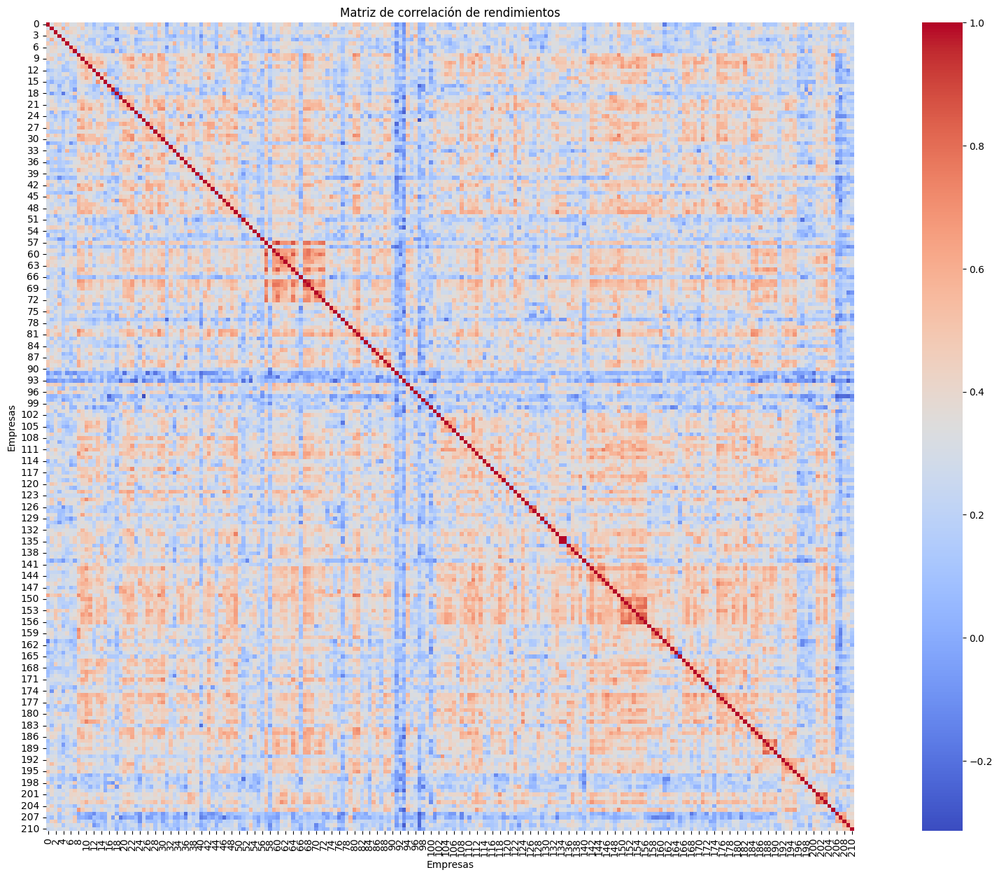

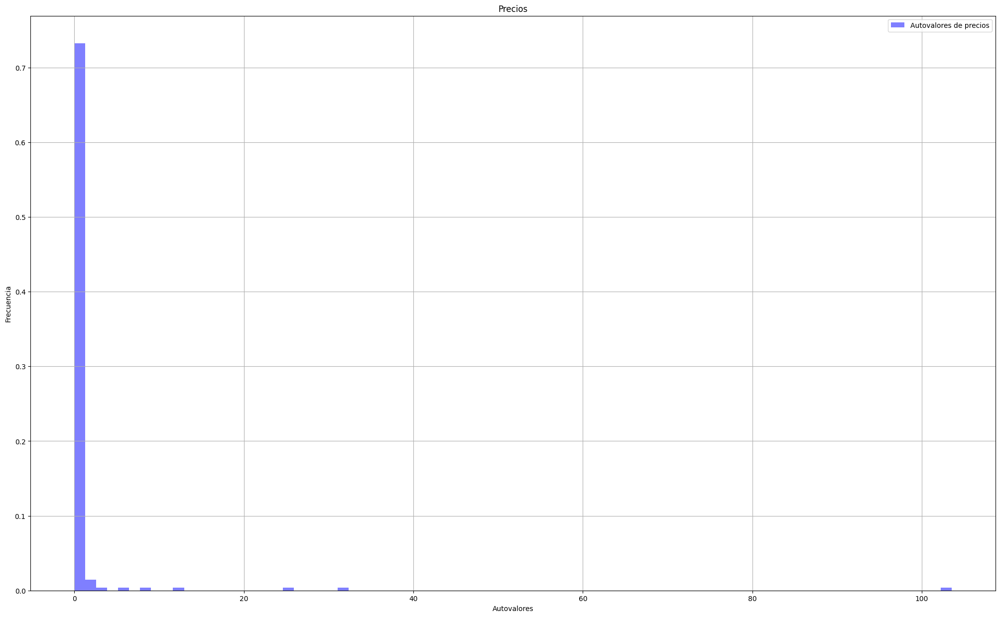

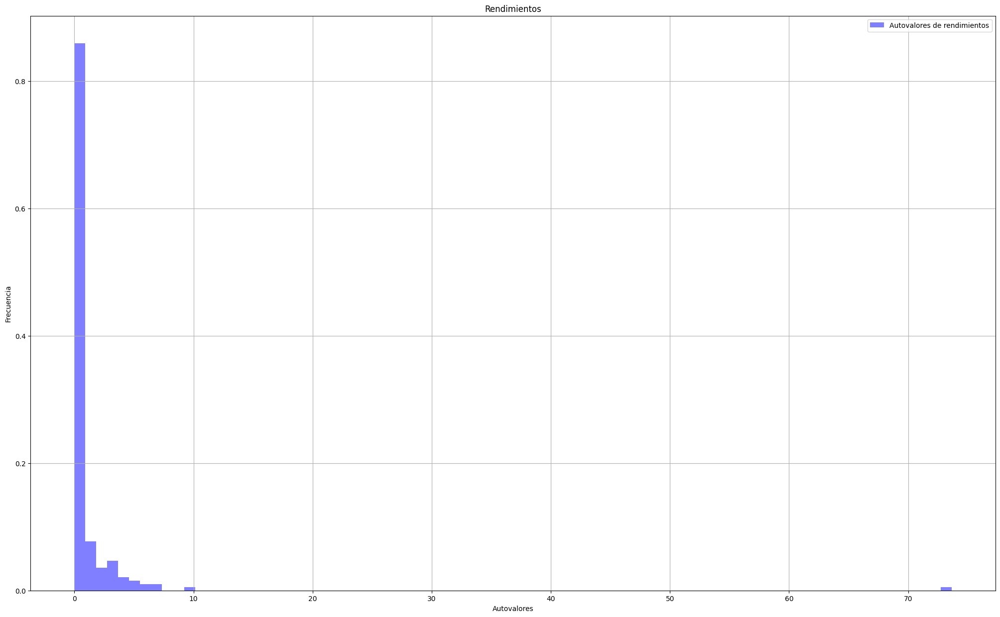

Época 5


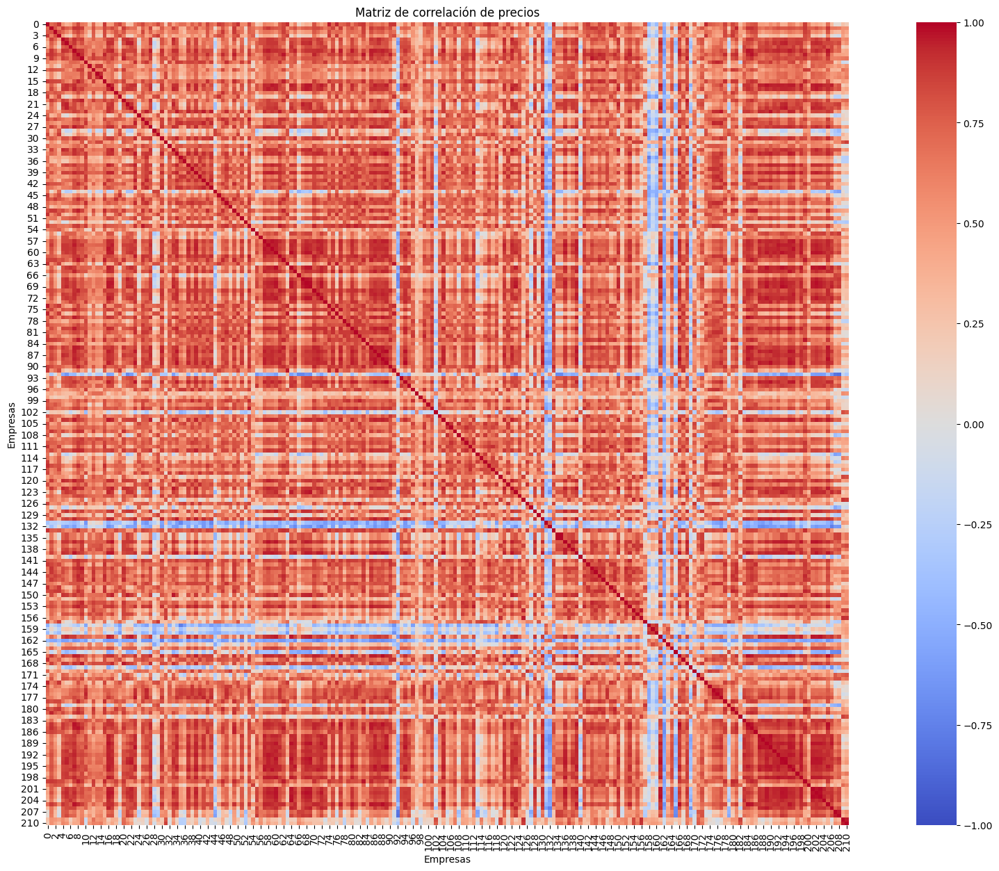

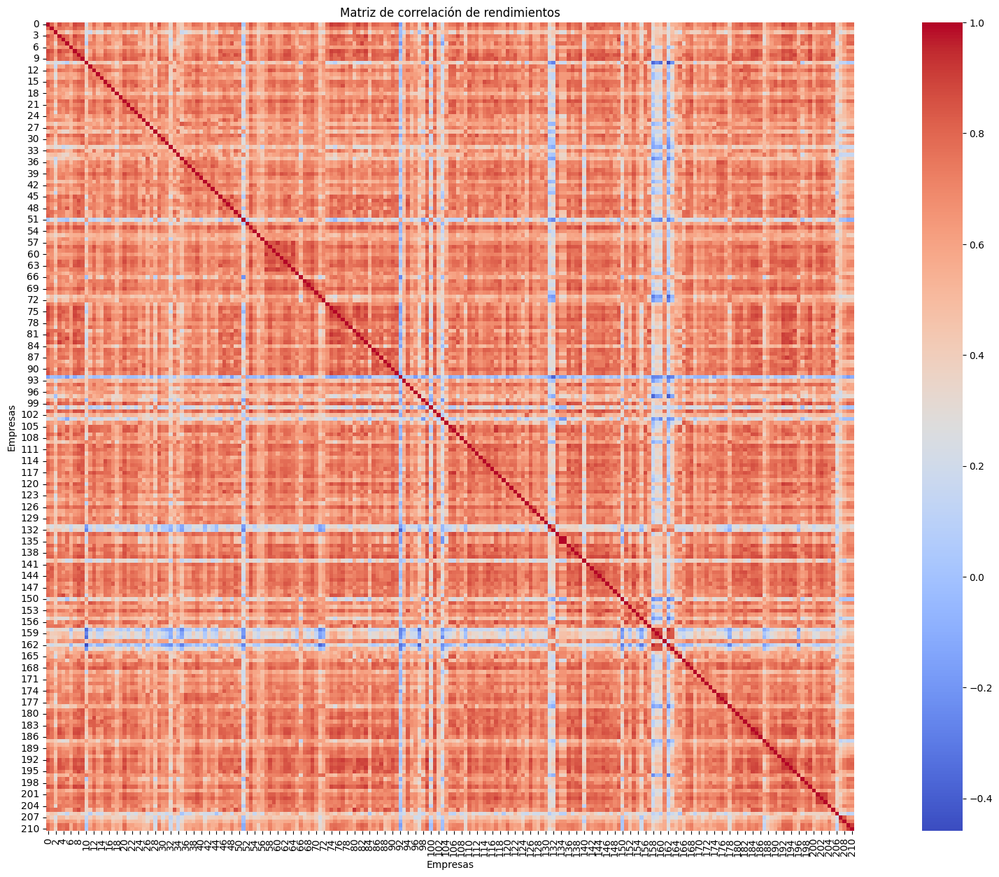

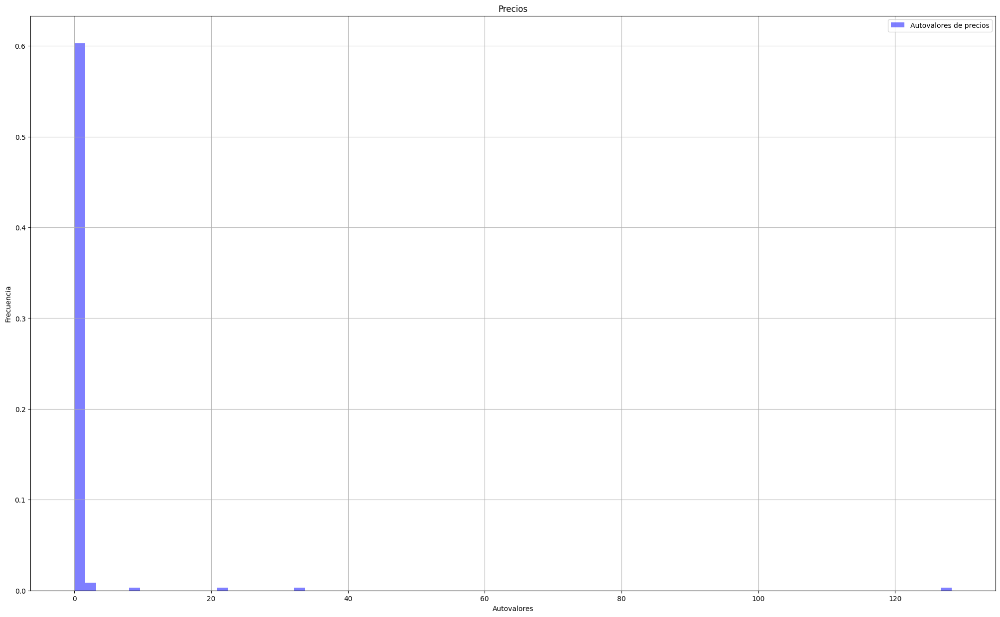

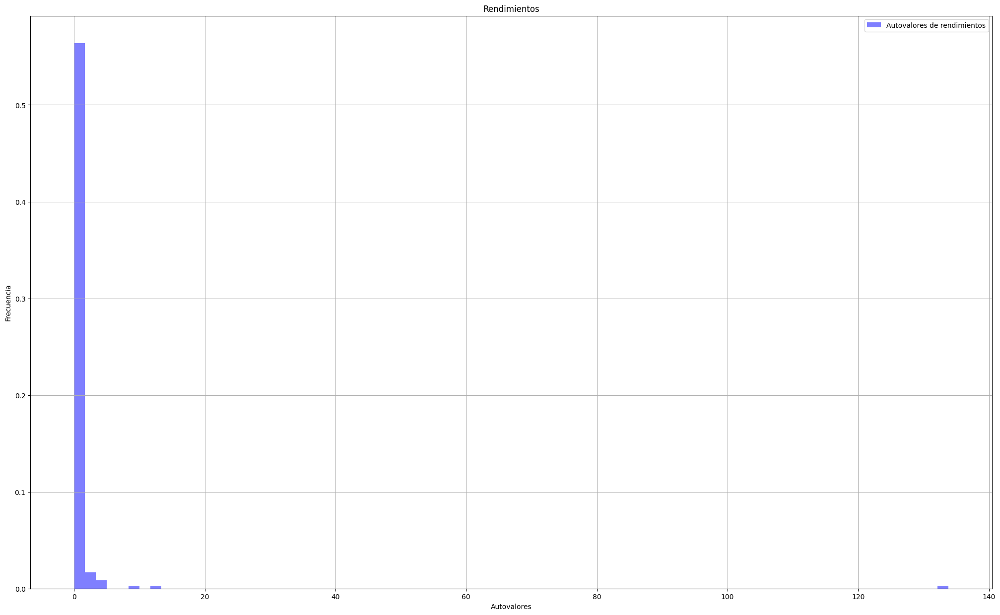

Época 6


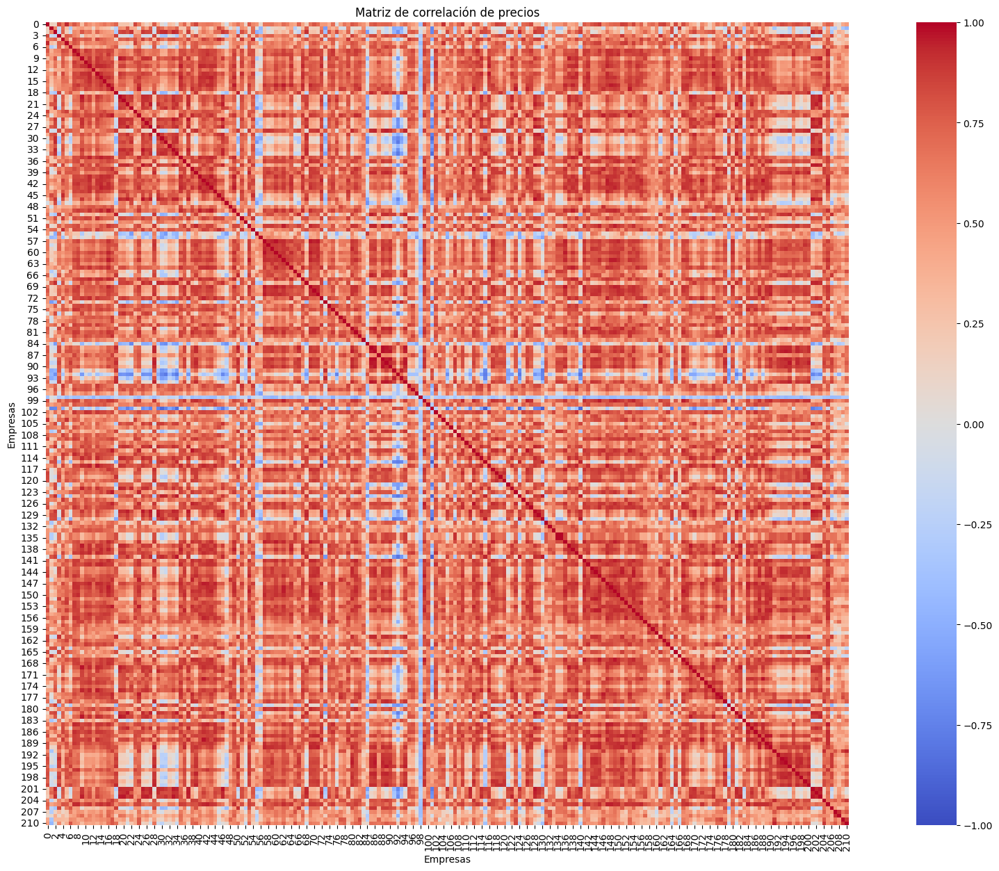

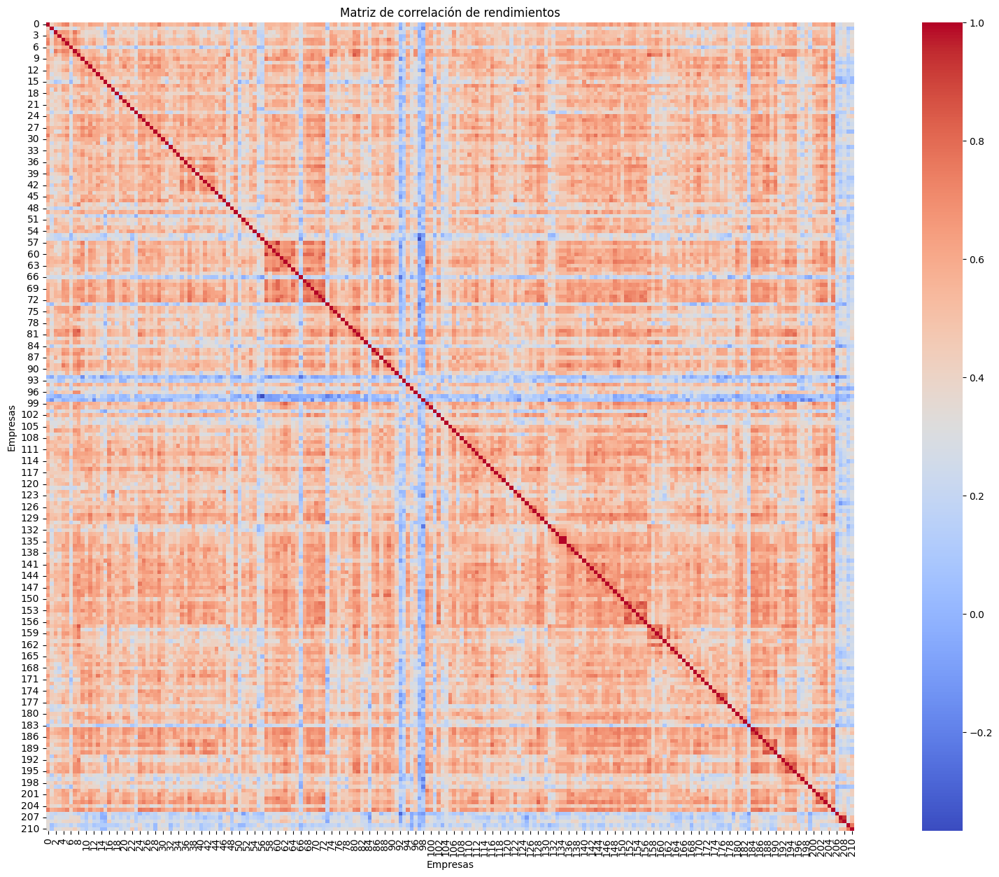

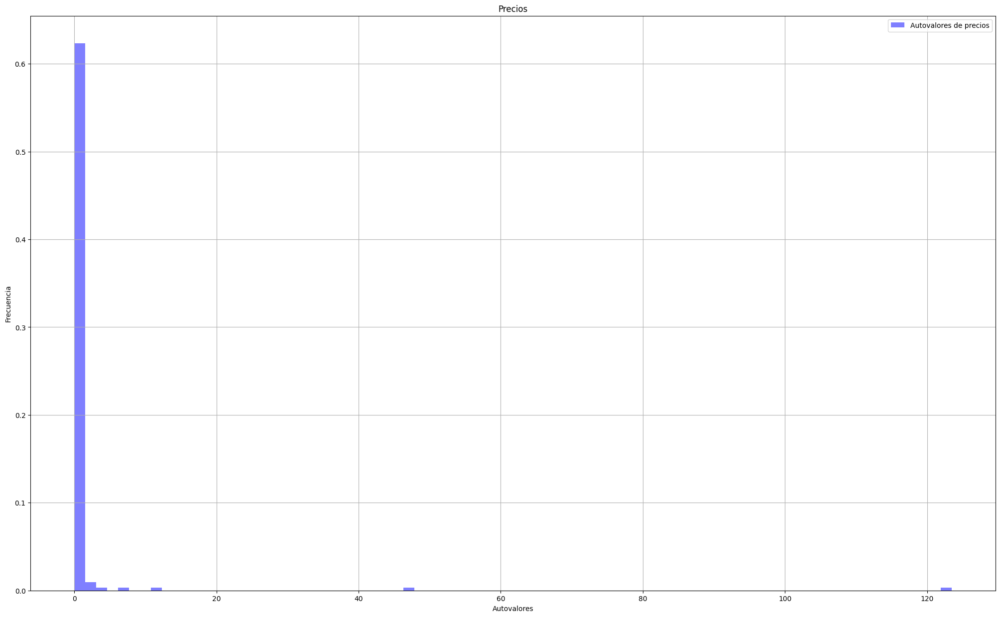

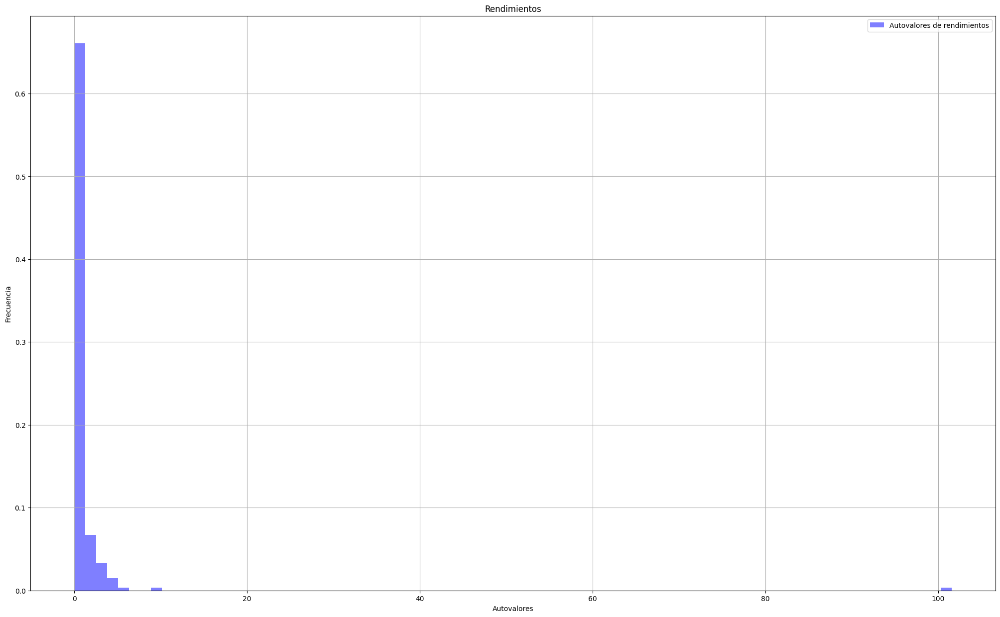

Época 7


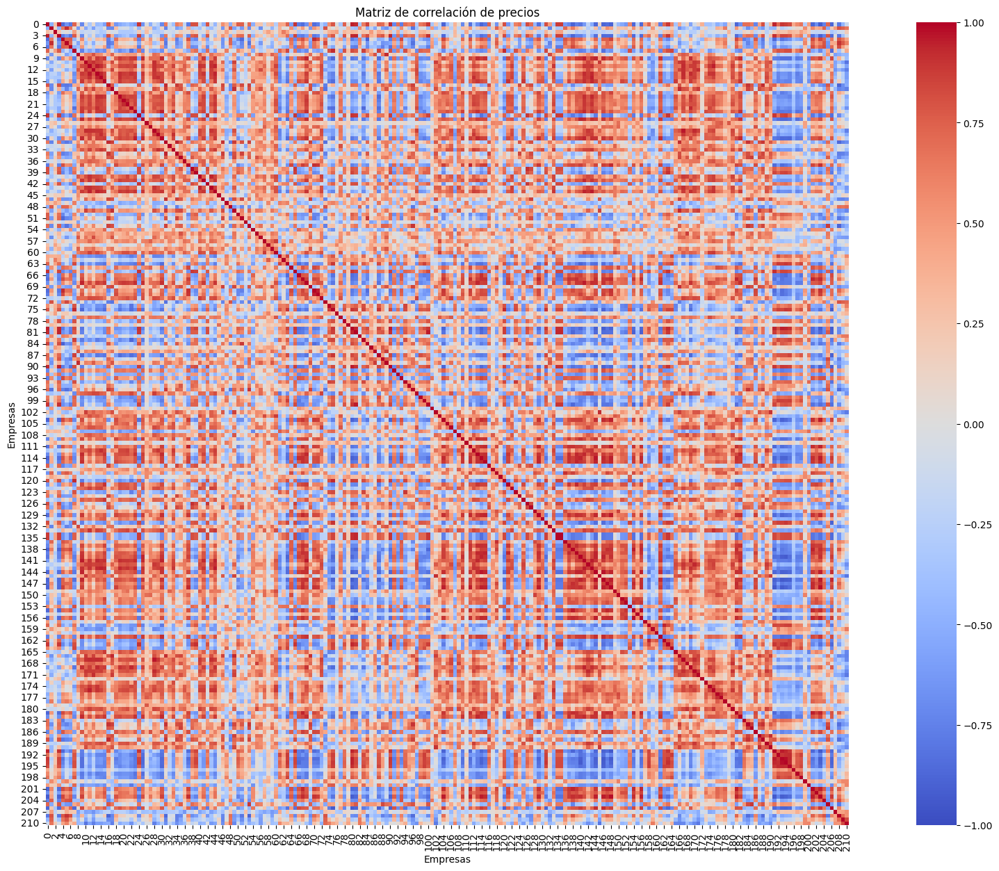

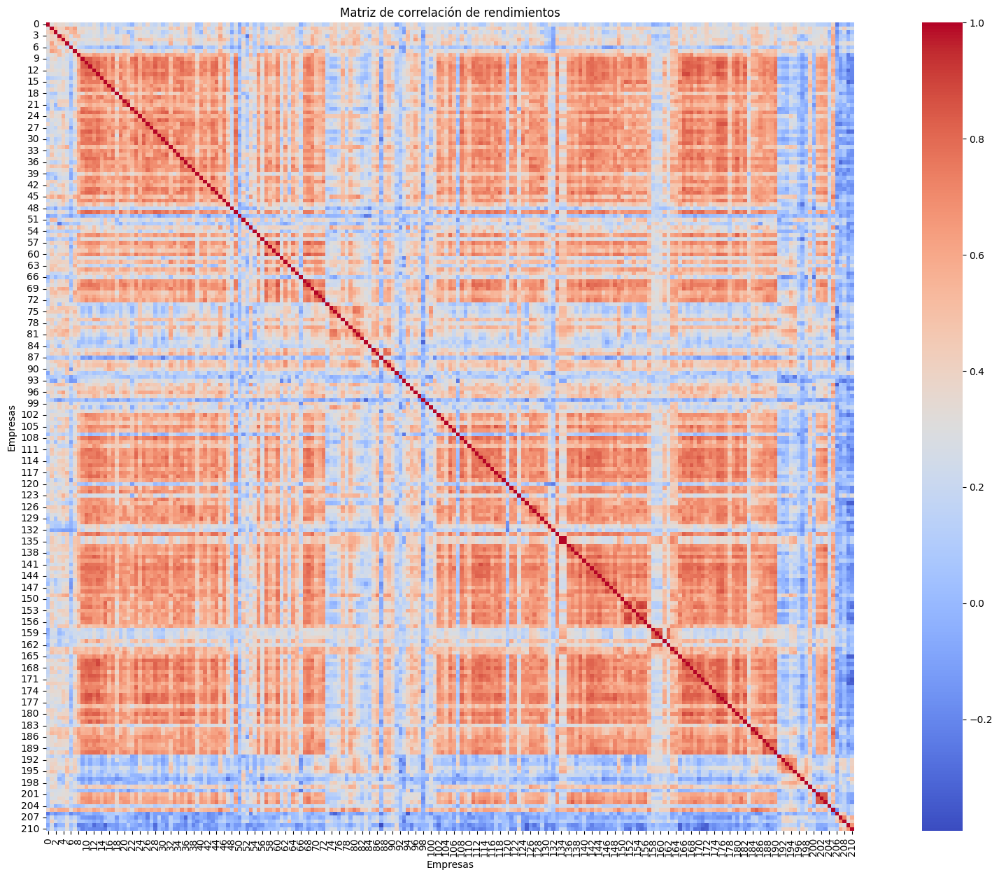

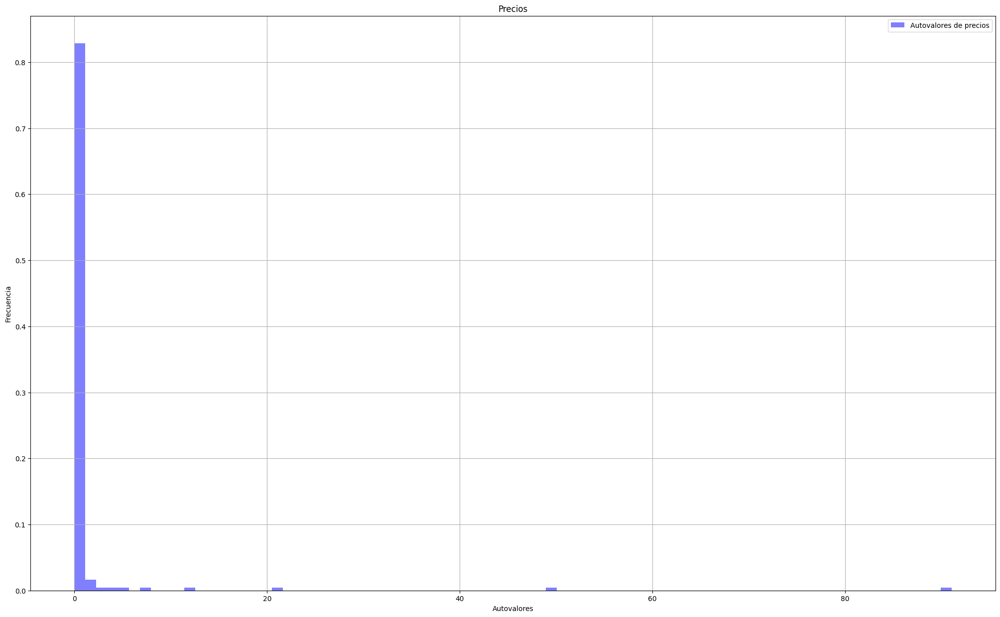

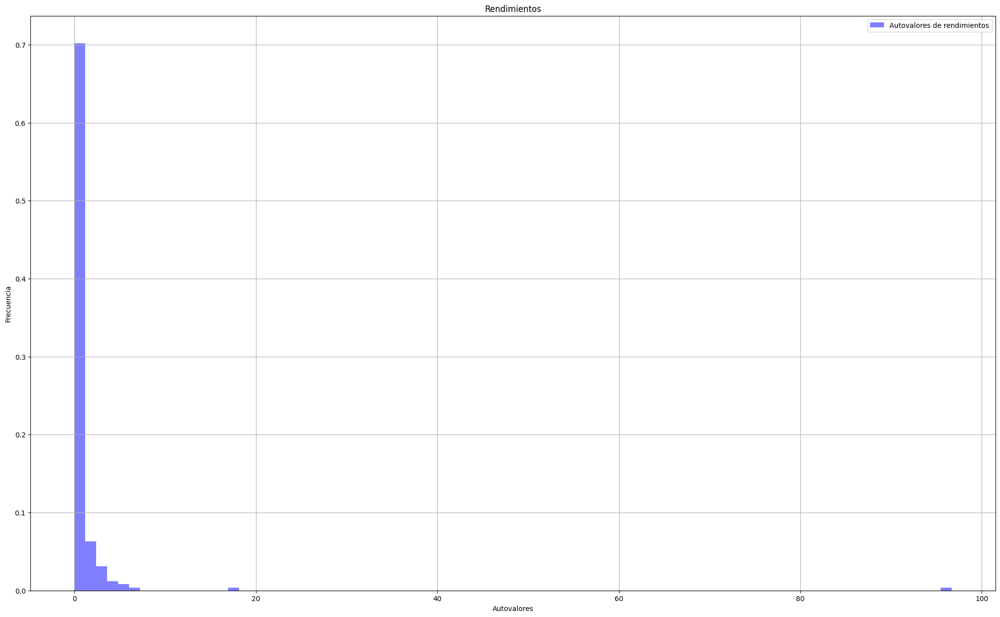

Época 8


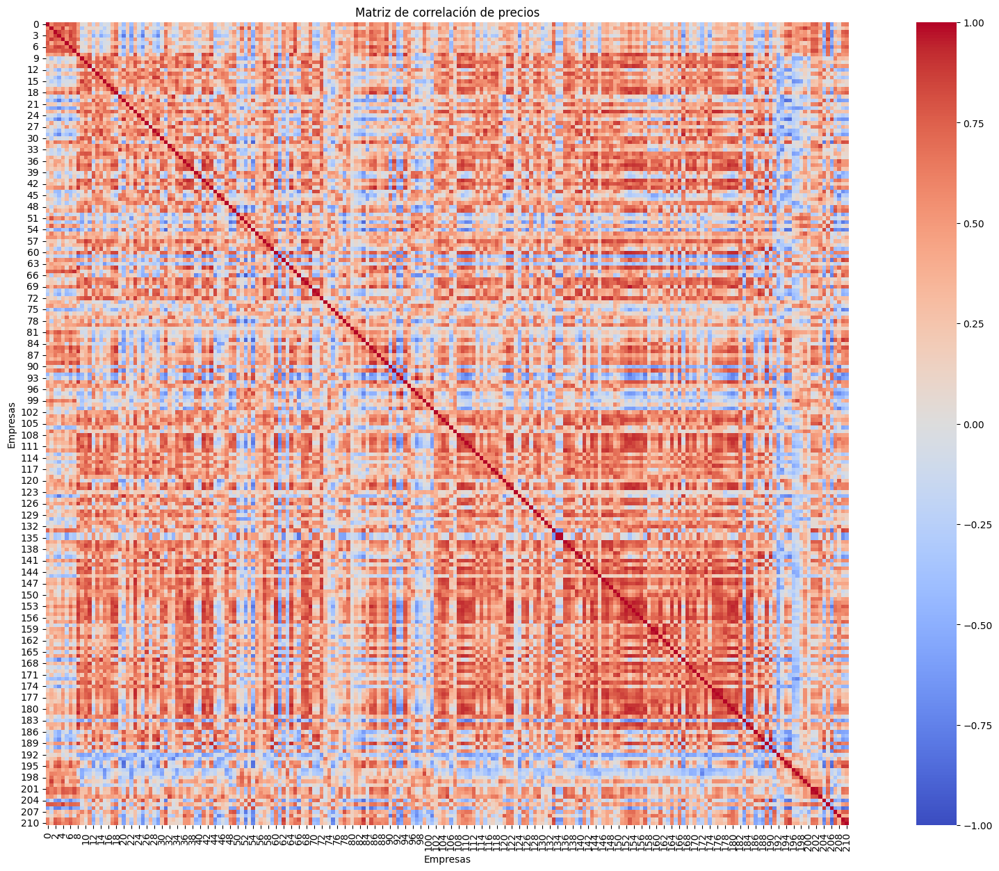

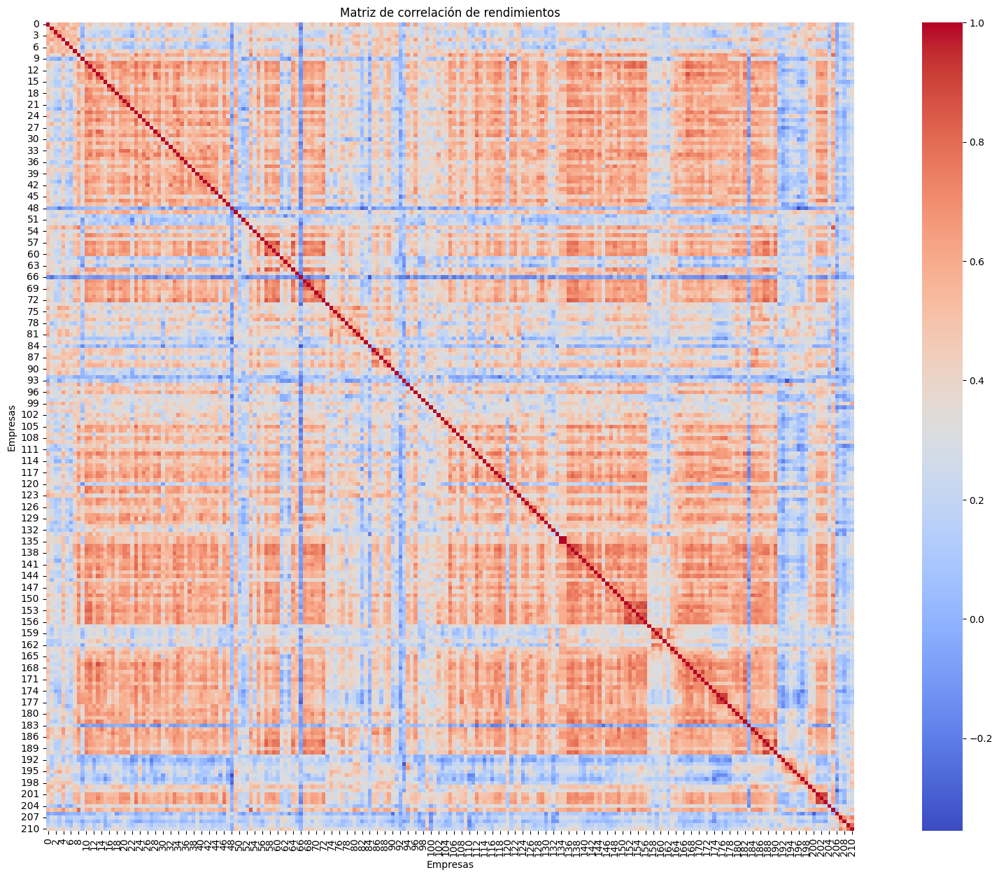

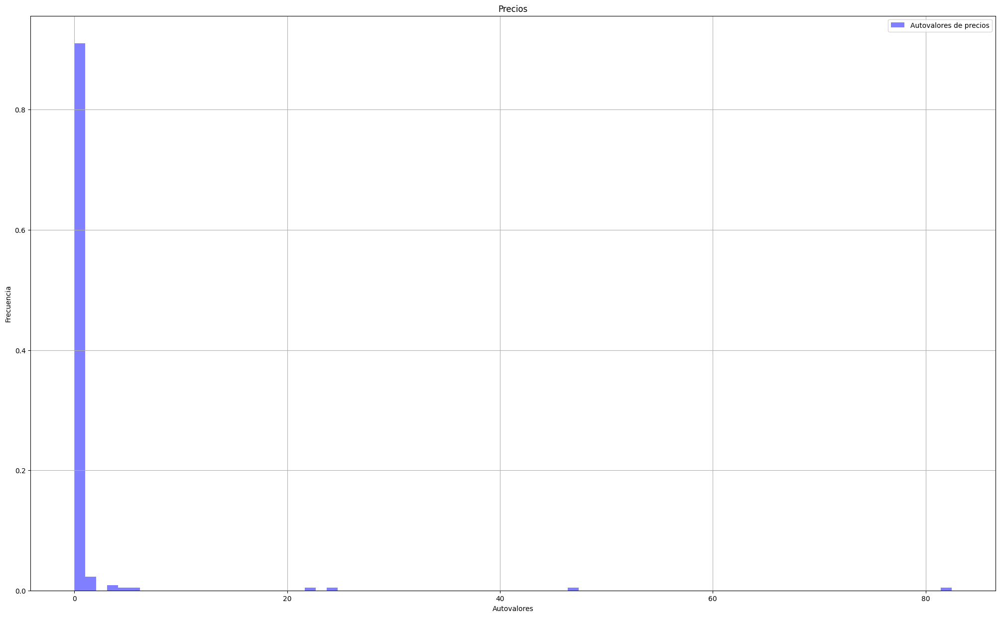

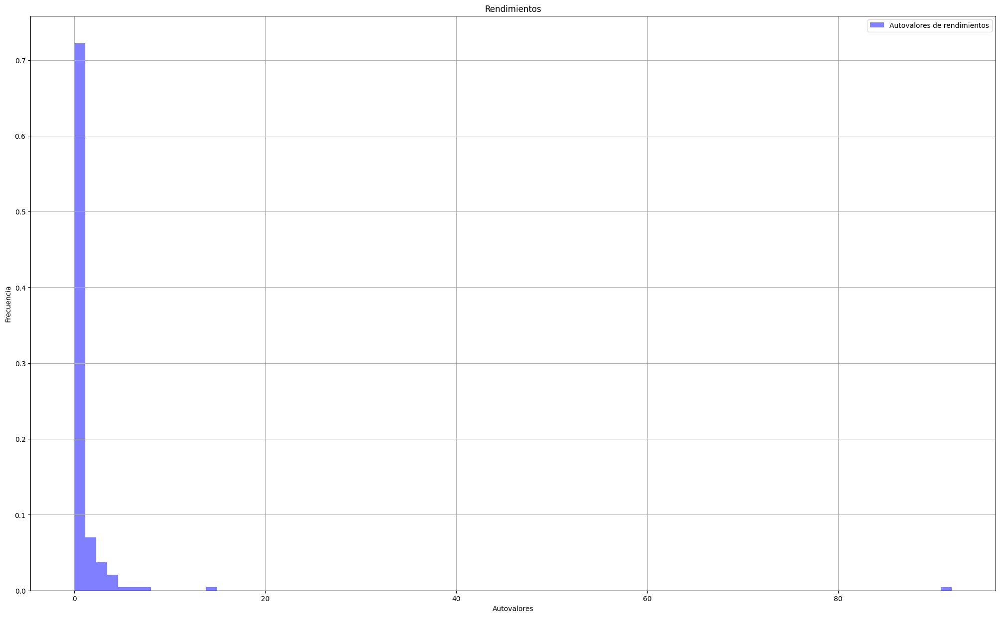

Época 9


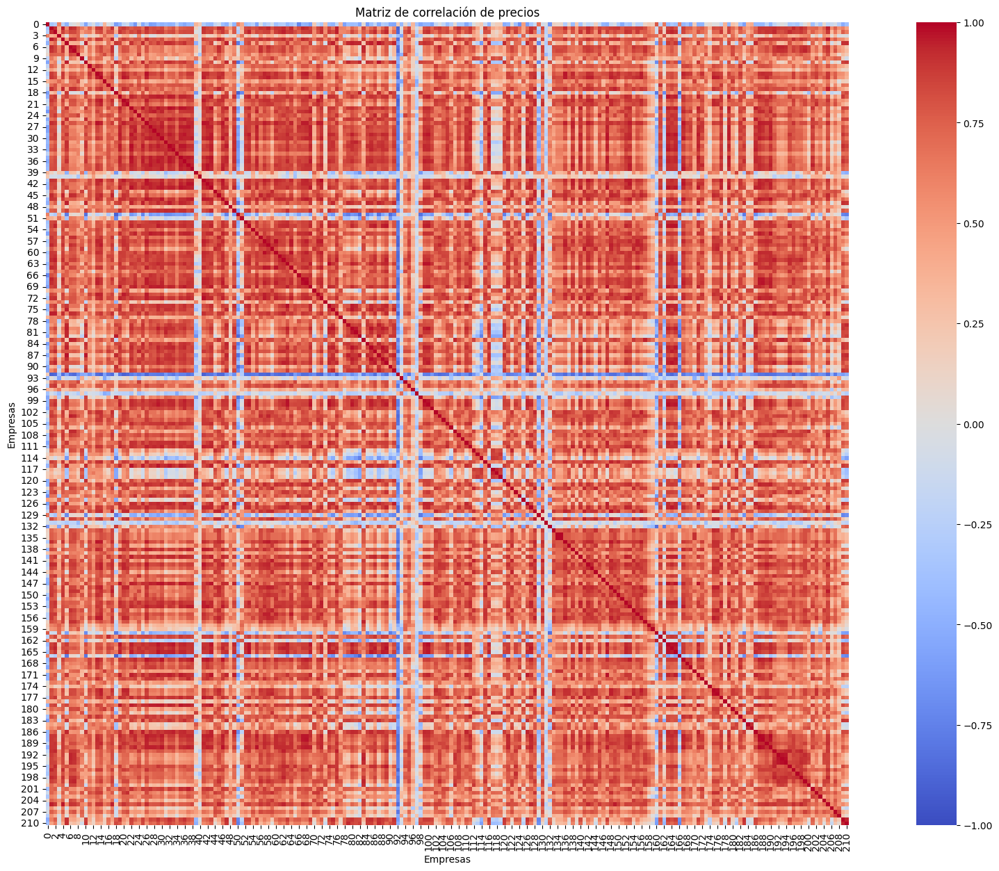

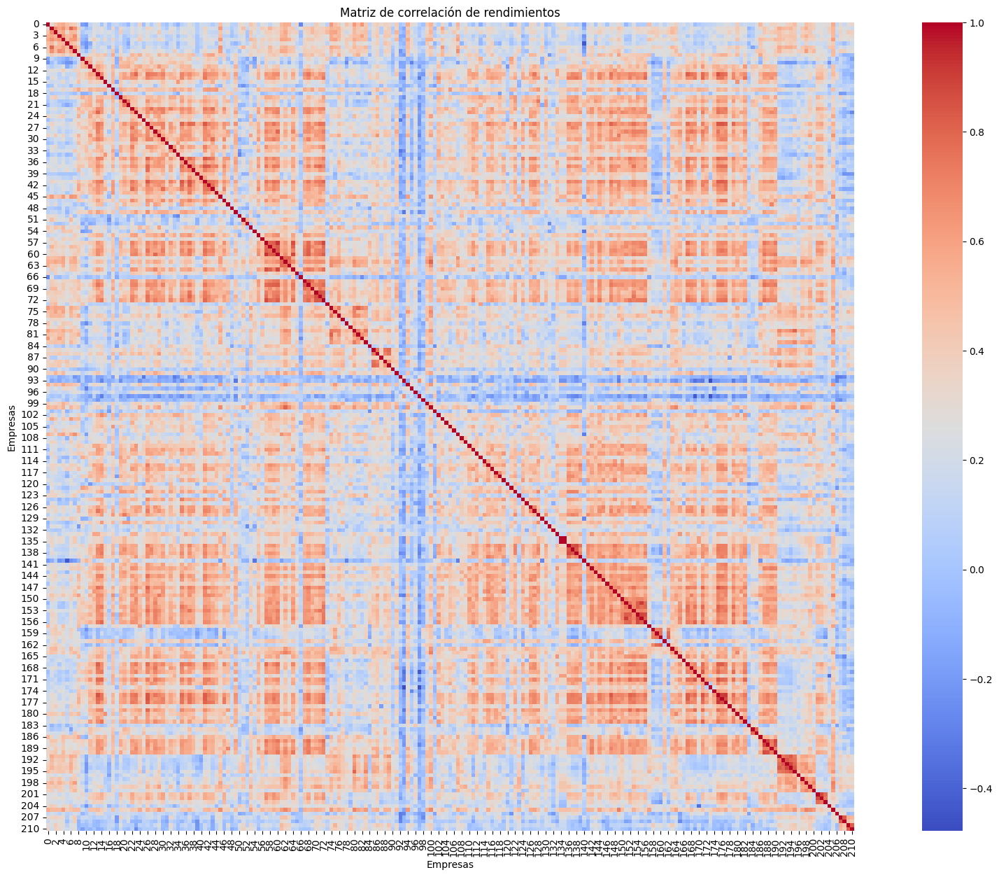

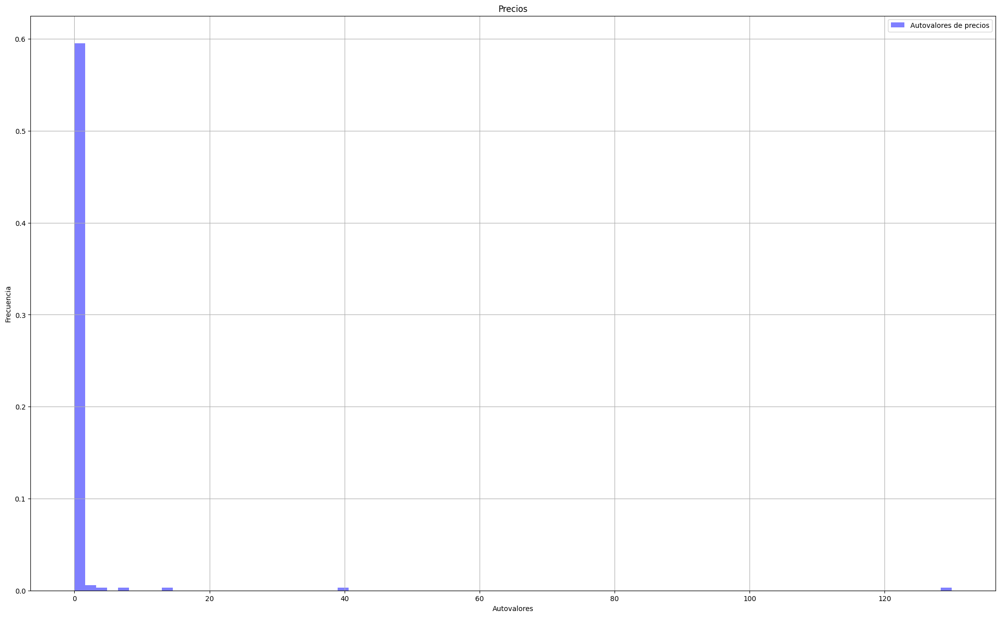

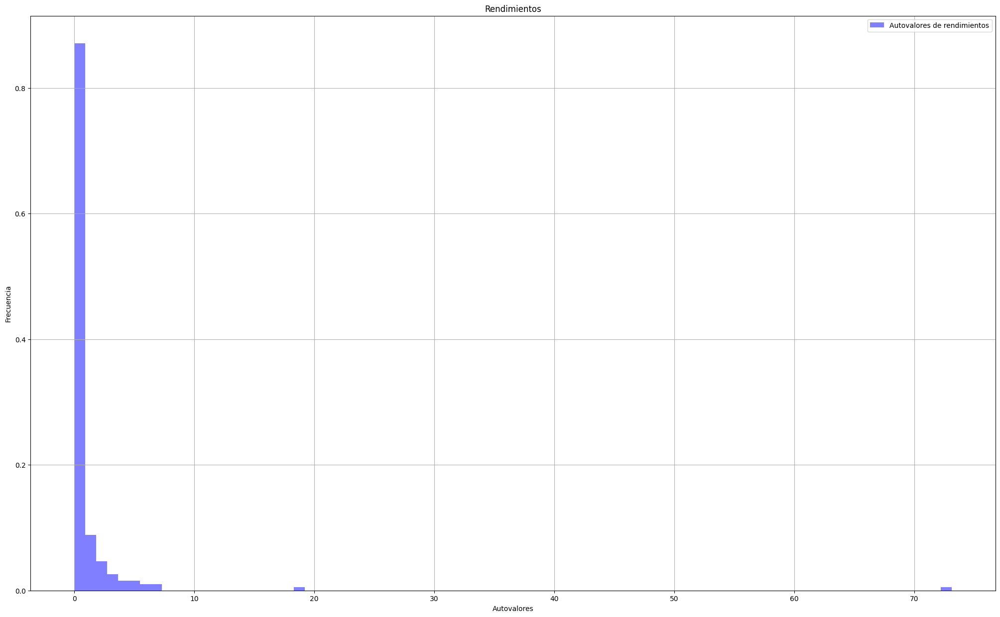

Época 10


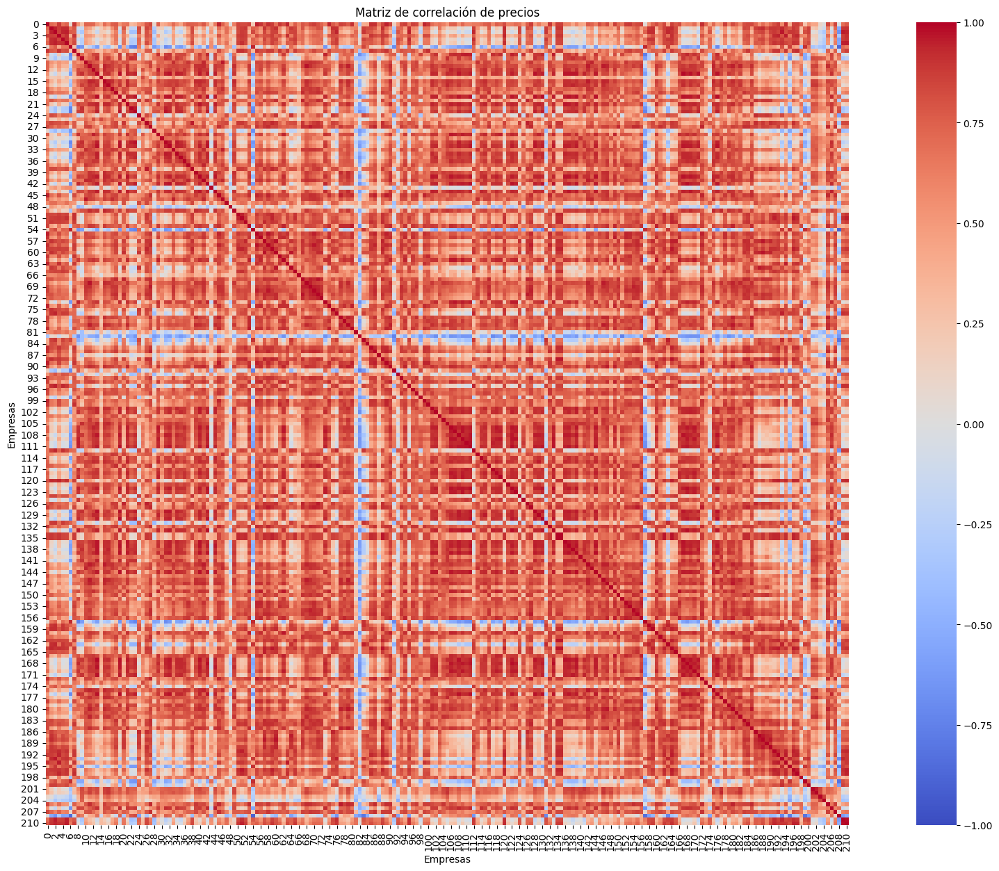

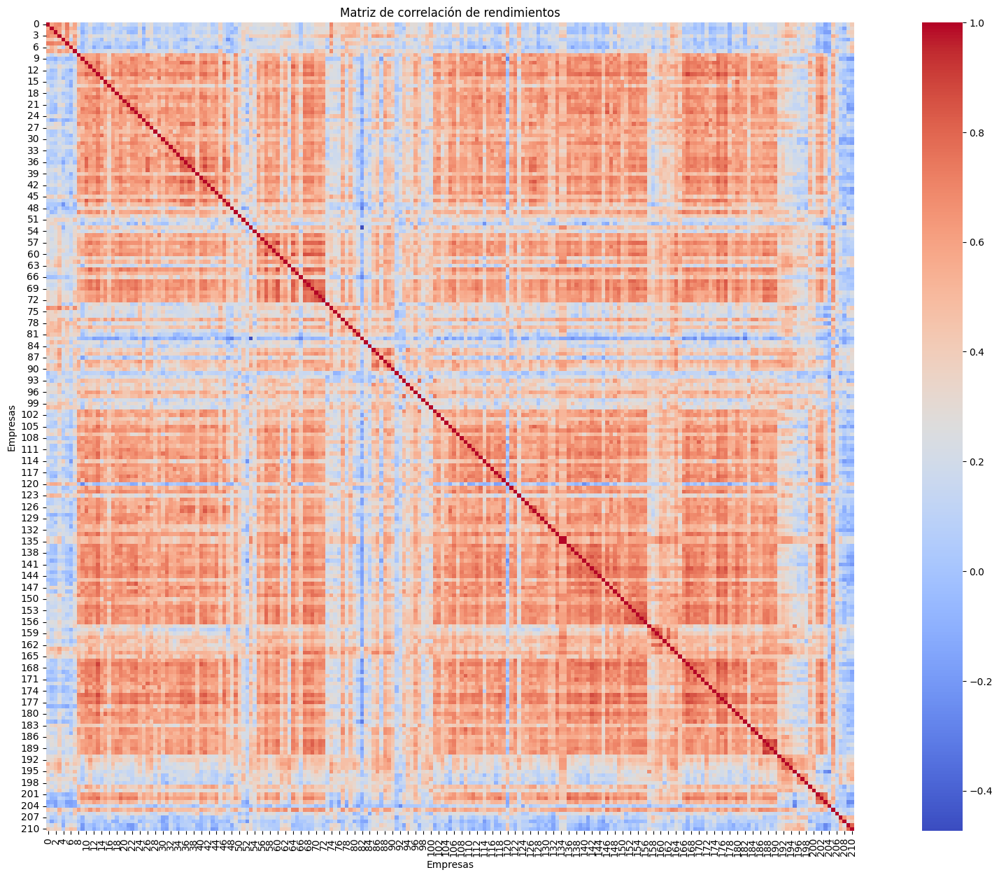

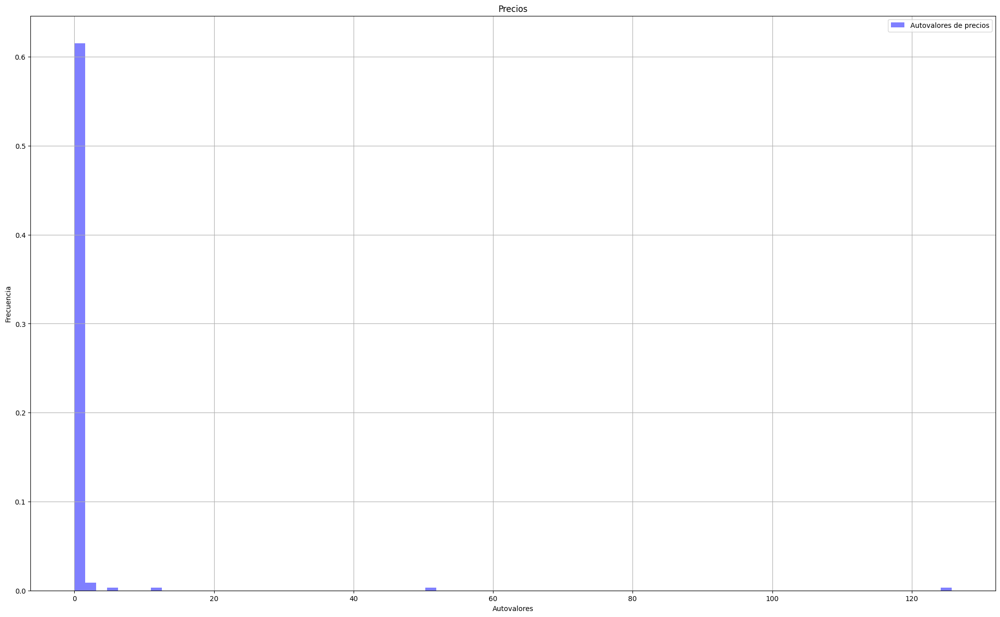

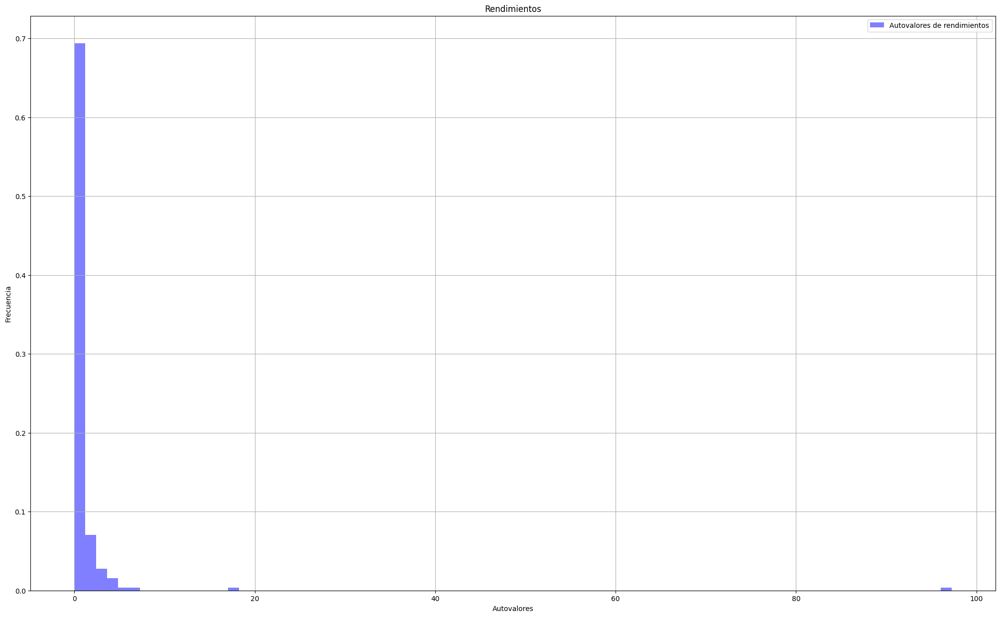

Época 11


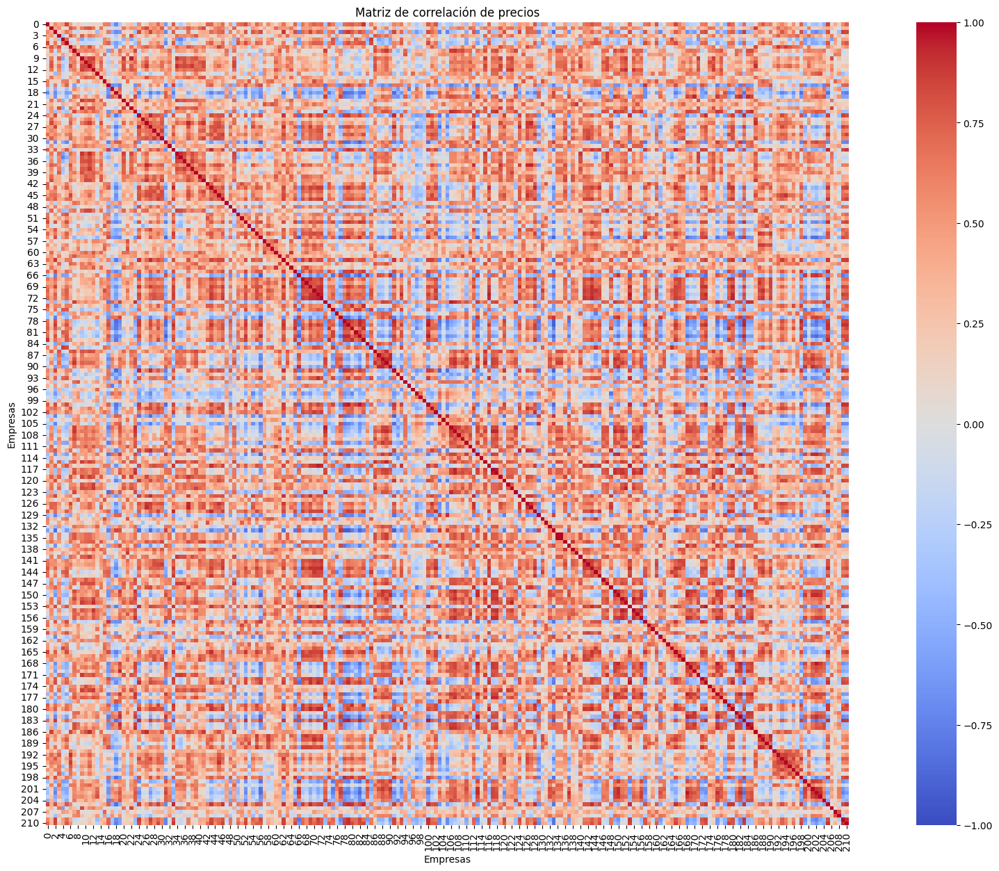

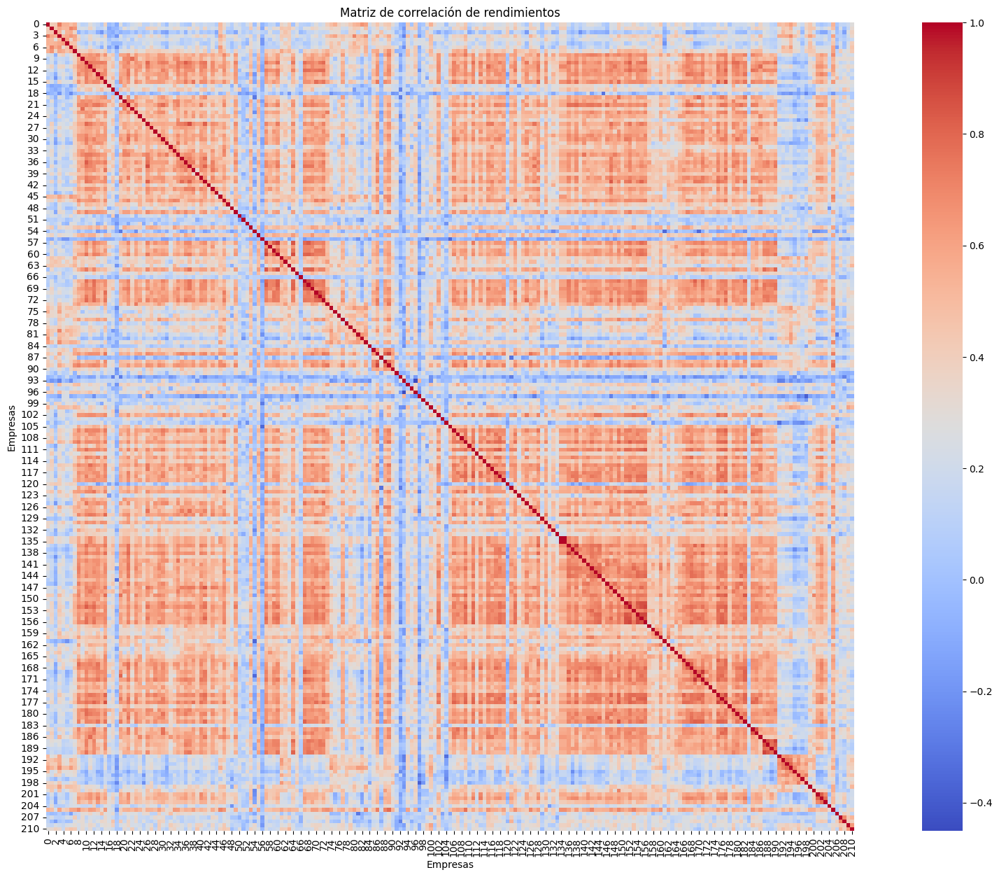

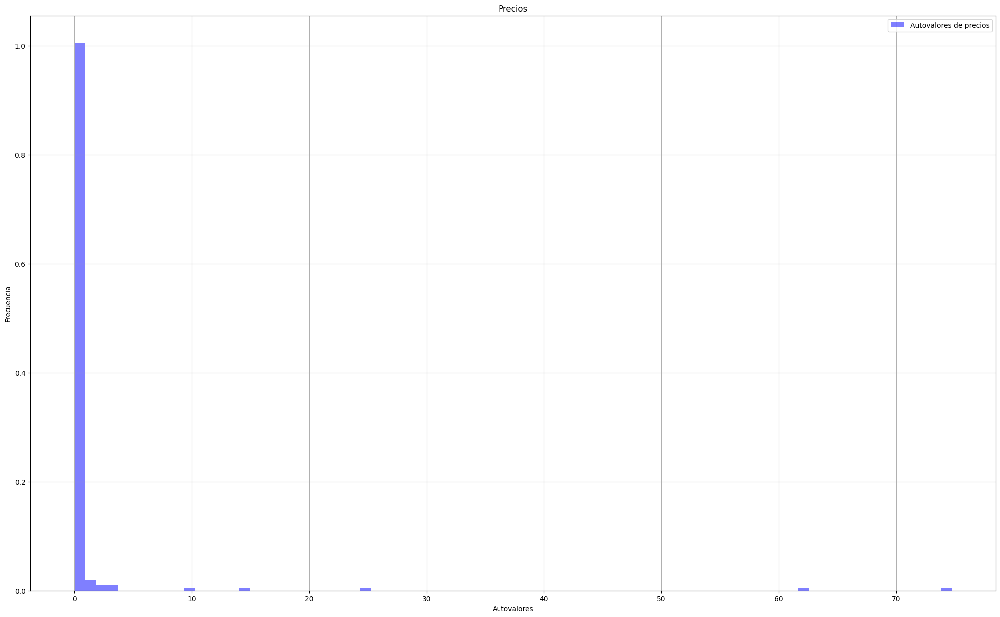

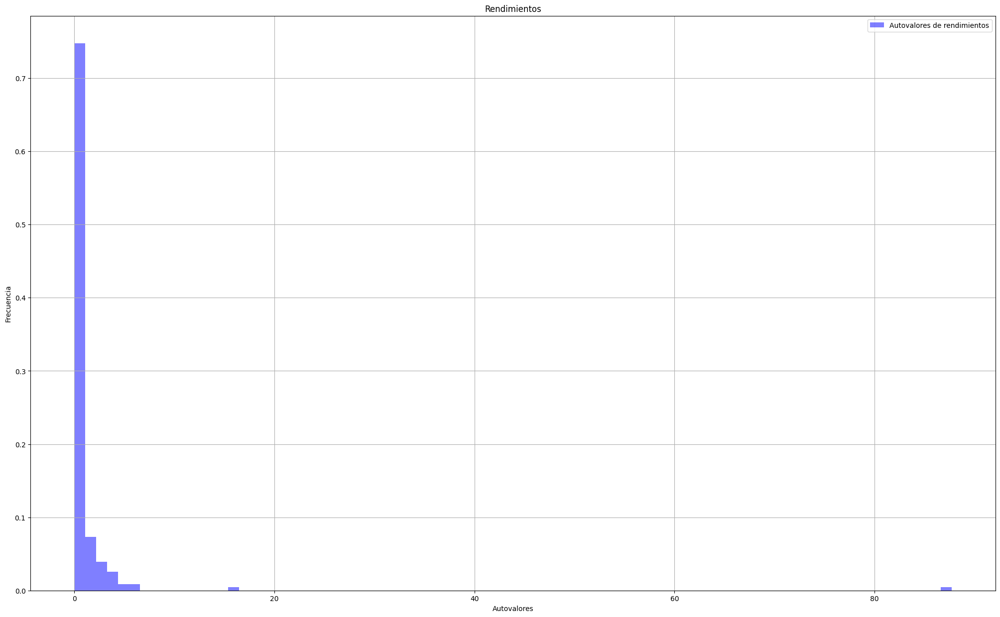

Época 12


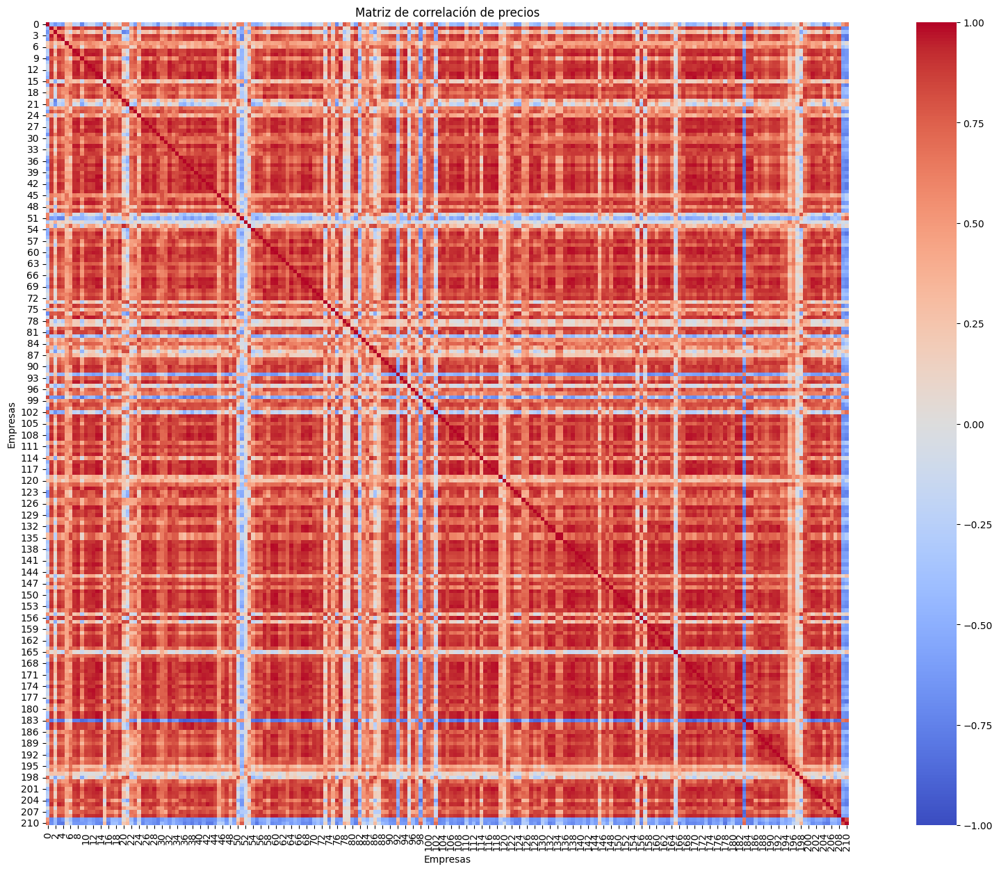

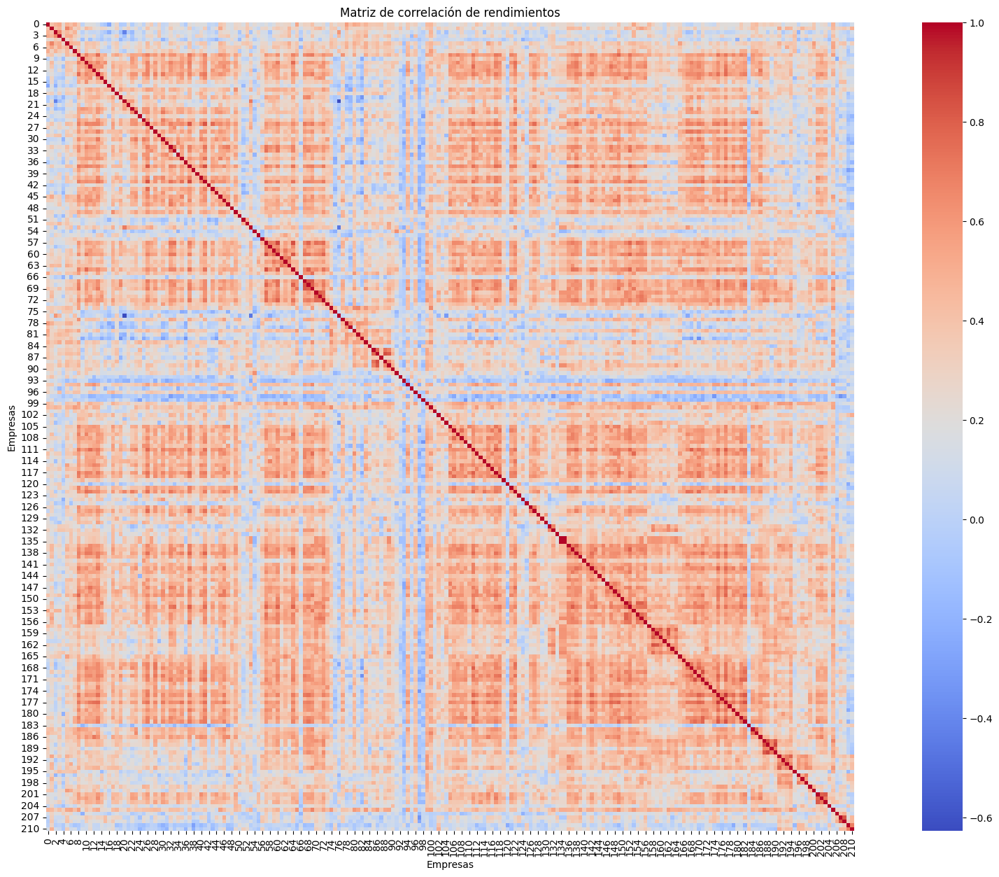

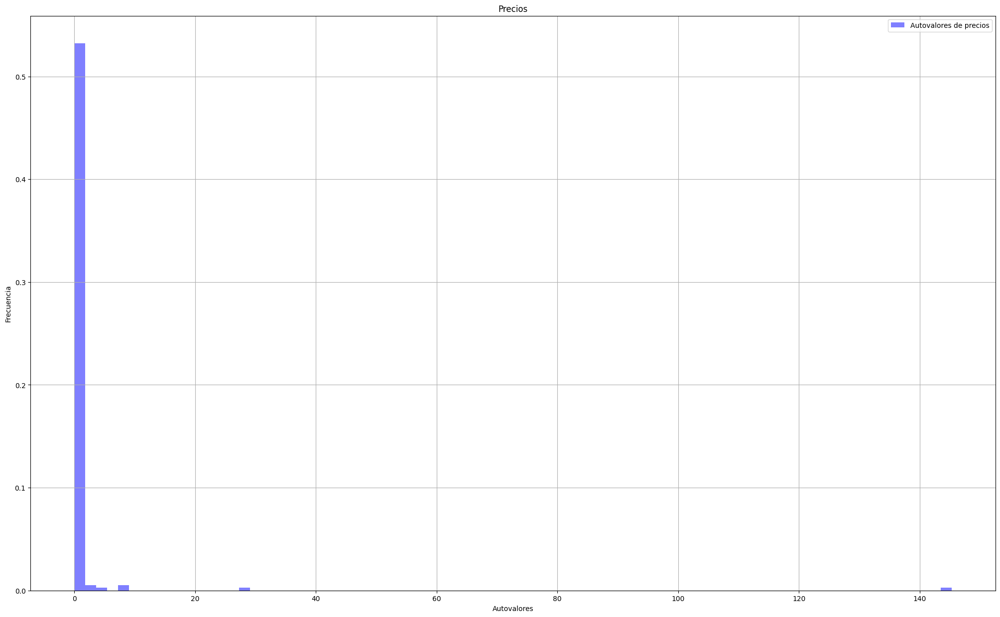

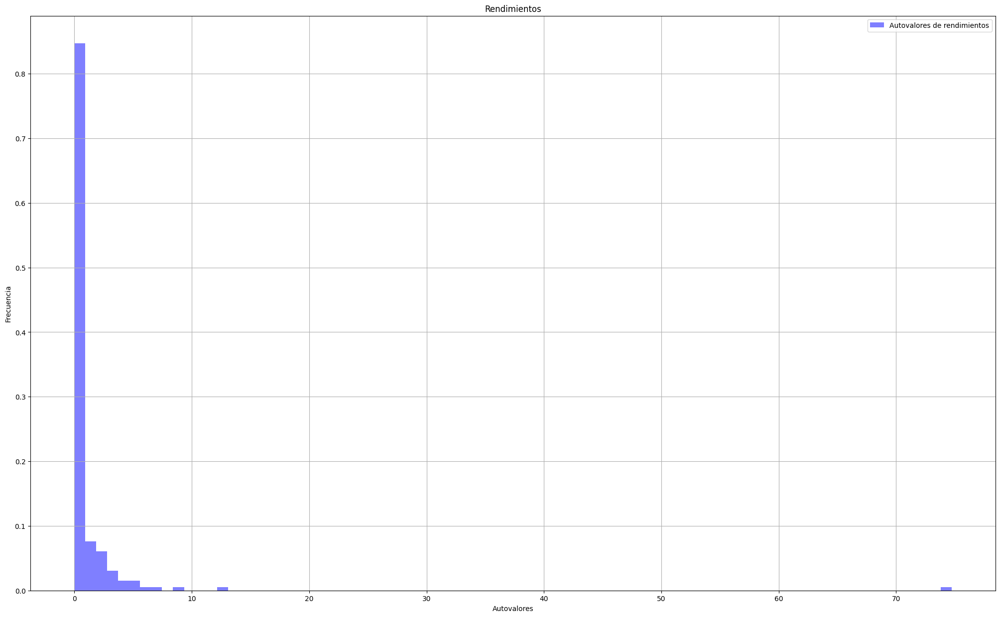

In [35]:
for i, df in enumerate(dataframes, start=1):
    if i == 3:
        continue
    print(f"Época {i}")
    analisis_nikkei(df)

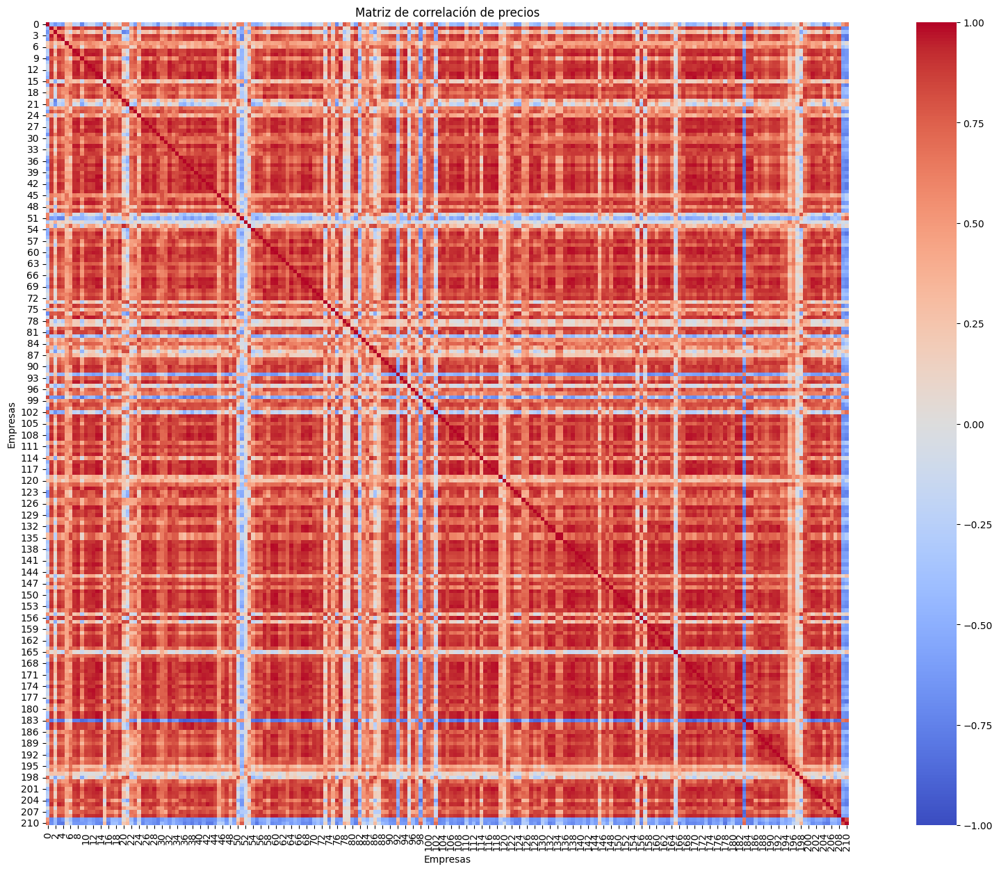

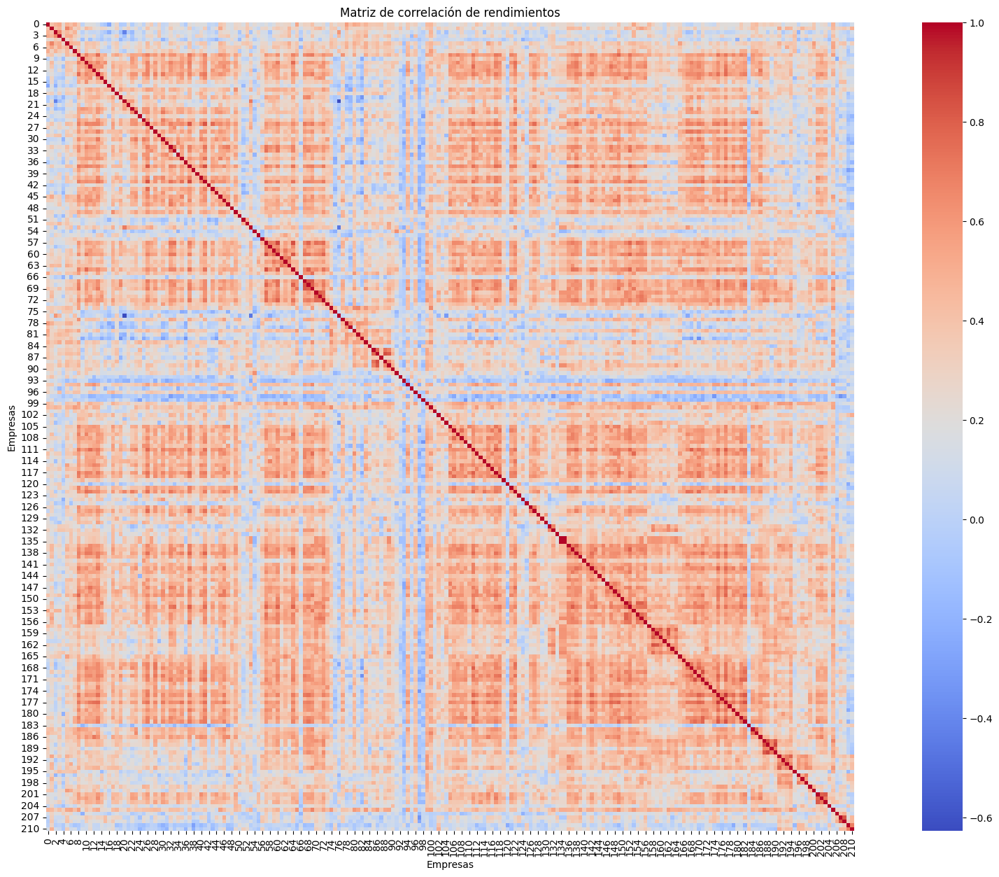

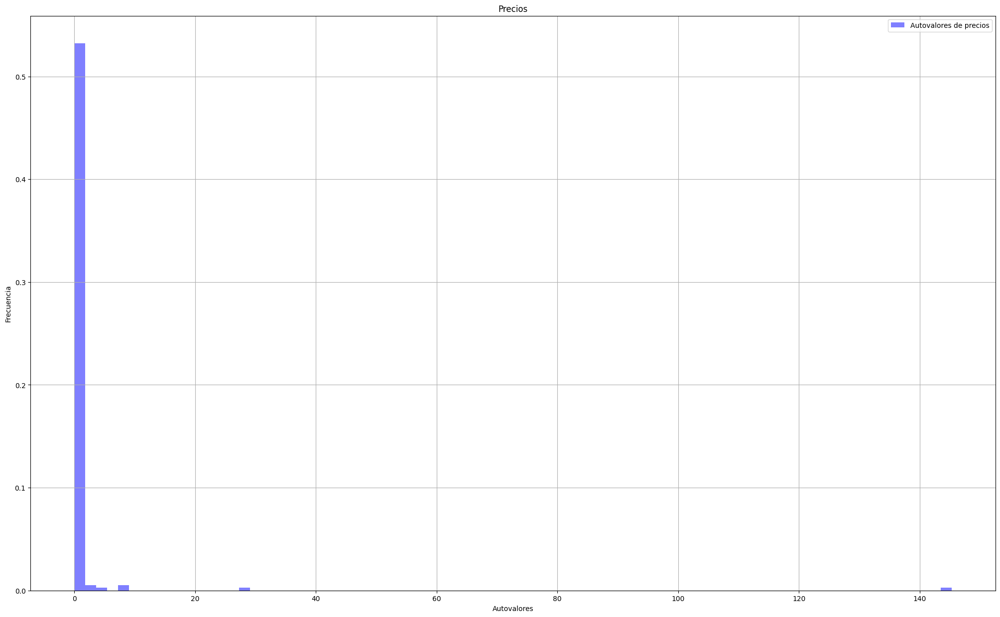

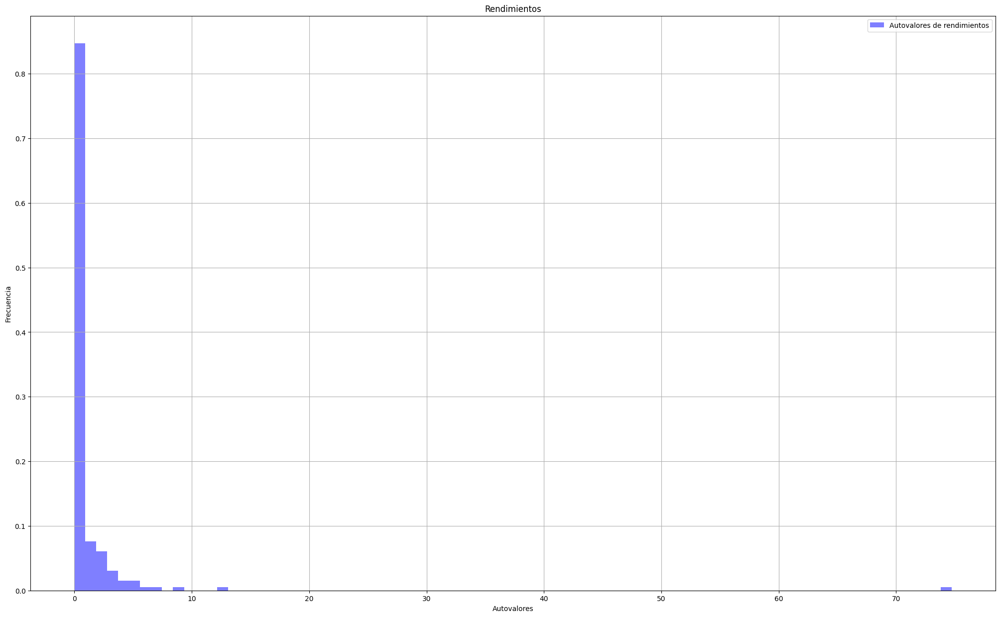

(     2012-10-09  2012-10-10  2012-10-11  2012-10-12  2012-10-15  2012-10-16  \
 0         943.0       915.0       916.0       925.0       913.0       928.0   
 1        3580.0      3525.0      3530.0      3535.0      3560.0      3565.0   
 2         777.0       759.0       759.0       769.0       756.0       760.0   
 3         846.0       835.0       831.0       844.0       839.0       843.0   
 4        1233.0      1213.0      1212.0      1238.0      1247.0      1255.0   
 ..          ...         ...         ...         ...         ...         ...   
 206       127.0       125.0       125.0       126.0       127.0       127.0   
 207       939.0       925.0       949.0       949.0       962.0       958.0   
 208       571.0       562.0       591.0       597.0       620.0       628.0   
 209      2110.0      2115.0      2140.0      2115.0      2125.0      2150.0   
 210      1665.0      1655.0      1680.0      1680.0      1670.0      1665.0   
 
      2012-10-17  2012-10-18  2012-10-

In [37]:
analisis_nikkei(df_13)

# Inciso c

In [43]:
def inciso_C(dataframes):

    correlaciones_promedio = []
    autovalores_maximos = []

    for df in dataframes:

        # Matriz de correlación de rendimientos
        C = C_def_rendimientos(df)

        # Correlación promedio sin considerar la diagonal
        N = C.shape[0]
        correlacion_promedio = (C.to_numpy().sum() - N) / (N * (N - 1))

        # Valor propio más grande
        autovalores = autovalores_rendimientos(C)
        autovalor_maximo = np.max(autovalores)

        # Guardar los resultados
        correlaciones_promedio.append(correlacion_promedio)
        autovalores_maximos.append(autovalor_maximo)

    # DataFrame de resultados
    df_resultados = pd.DataFrame({
        "Época": range(1, len(dataframes) + 1),
        "Correlación promedio": correlaciones_promedio,
        "Autovalor máximo": autovalores_maximos
    })

    # Diagrama de dispersión
    plt.figure(figsize=(10, 6))
    plt.scatter(correlaciones_promedio, autovalores_maximos, color="blue")

    # Identificar cada época
    for i in range(len(dataframes)):
        plt.annotate(
            str(i + 1),
            (correlaciones_promedio[i], autovalores_maximos[i]),
            xytext=(5, 5),
            textcoords="offset points"
        )

    plt.title("Correlación promedio vs. autovalor máximo")
    plt.xlabel("Correlación promedio")
    plt.ylabel("Autovalor máximo")
    plt.grid()
    plt.show()

    return df_resultados

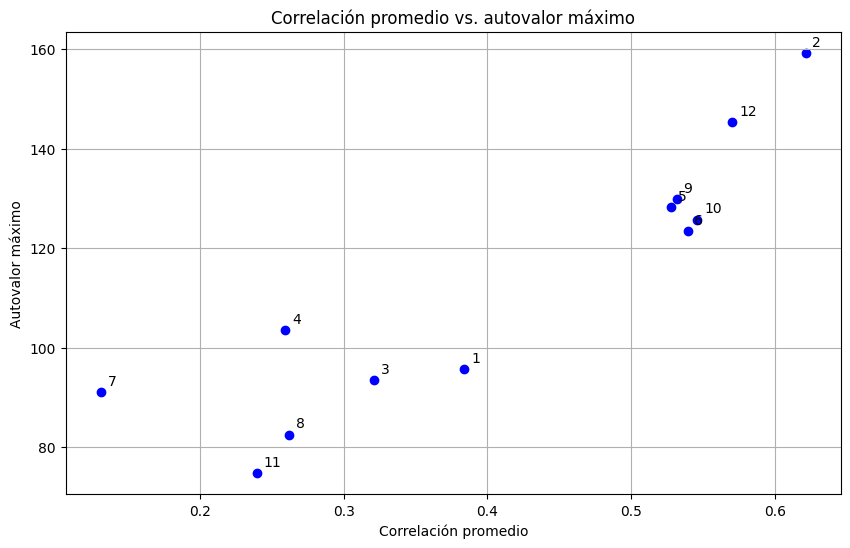

In [44]:
dataframes = [df_1, df_2,df_4, df_5, df_6, df_7, df_8, df_9, df_10, df_11, df_12, df_13]
df_resultados = inciso_C(dataframes)

En el diagrama de dispersión se observa una tendencia positiva entre la correlación promedio y el valor propio máximo de las matrices de correlación. Esto indica que, conforme aumenta la correlación entre los rendimientos de las empresas, también aumenta el valor propio más grande, lo que refleja un comportamiento colectivo más fuerte del mercado.

En particular, las épocas 2 y 12 presentan las correlaciones promedio y los valores propios máximos más elevados, mientras que las épocas 7, 8 y 11 muestran valores considerablemente menores. Este comportamiento sugiere que, durante ciertas épocas, las empresas tienden a fluctuar de manera más sincronizada, fenómeno que puede intensificarse durante periodos de inestabilidad financiera.